# **Machine Learning-Based Flight Anomaly Detection Incorporating Arrival Airport and Runway Context**

## **PROJECT SUMMARY**

The primary objective of this project was to develop and compare different machine learning models to detect flight anomalies for commercial aircraft.
The second objective was to determine the factors contributing to the risk of flight anomalies. The project used the **NASA DASHlink Multi-Class Anomaly Classification Dataset**. The dataset is publicly available through the **[NASA DASHlink repository](https://c3.nasa.gov/dashlink/projects/85/)**. It contains flight trajectories during approach to landing classified as **Nominal, Speed High, Path High, and Flaps Late**. For this project, the three anomalous classes were combined into a single anomaly class to formulate the problem as binary anomaly detection. The time-series observations for each flight were then aggregated into flight-level features using the **mean and standard deviation** of the selected flight variables.

Exploratory data analysis showed that anomalous flights accounted for **10%** of the total observations, indicating that the resulting binary target variable was **imbalanced**. Several supervised and unsupervised machine learning algorithms were fitted and compared, including:  

- Balanced Random Forest (**BRF**)
- Isolation Forest (**IF**)
- Extreme Gradient Boosting Classifier (**XGBoost**) *(with/without SMOTE resampling)*
- Autoencoder (**AutoEnc**)
- Logistic Regression (**LG**) *(with/without SMOTE resampling)*
- Artificial Neural Networks (**NN**)  

The training set was used for model development and hyperparameter tuning, while the test set was reserved for final performance evaluation. Model performance was assessed using three widely adopted classification metrics: **precision**, **recall**, and **F1-score**. Given the class imbalance in the dataset, particular emphasis was placed on recall and F1-score, as they provide more informative measures of the model’s ability to identify the minority (anomaly) class than overall classification accuracy.  

The comparative analysis demonstrated that **XGBoost achieved the highest predictive performance**, closely followed by the **Neural Network** and **Balanced Random Forest** models, highlighting the effectiveness of ensemble and deep learning approaches for this classification task.  

Among the six candidate models, **XGBoost demonstrated the strongest overall performance**, achieving the highest F1-score (**0.790**) while maintaining high Precision (**0.821**) and Recall (**0.762**). Accordingly, **XGBoost was selected as the final model** for anomaly detection. However, **Balanced Random Forest (BRF)** achieved the highest Recall (**0.921**) and may be preferable in cases where minimizing missed anomalies is prioritized over reducing false-positive detections.

---

The **SHAP analysis** identified `airspeed_mean` as the most influential predictor, followed by `tot_pressure_std`, `altitude_std`, and `airspeed_std`. Higher values of `airspeed_mean` and `altitude_std` were generally associated with **increased anomaly predictions**, whereas higher values of `tot_pressure_std` and `airspeed_std` were associated with **decreased anomaly predictions**. Overall, the results highlight **airspeed, total-pressure variability, and altitude variability** as key contributors to the XGBoost anomaly predictions.


---

**Project Merit**

The primary contribution of this project is that it has incorporated **arrival airport** and **runway** into the predictive model as contextual features. This distinguishes it from prior studies that relied primarily on flight-specific characteristics. The inclusion of the two factors above improved prediction performance by **about 10%**.

Another contribution of this project is the application of **SHAP (SHapley Additive exPlanations)** to interpret the final XGBoost model and identify the factors that contribute to anomaly predictions. Rather than evaluating the model solely on predictive performance, the SHAP analysis provides insight into the **relative importance and direction of influence of individual predictors** on the model output. This enables the interpretability of the anomaly-detection framework and provides a better understanding of the flight characteristics and operational factors associated with predicted anomalous behavior.


---
---
---
---

## **Dataset Description**

### **Target Variable Distribution and Binary Classification**

| Class Index | Original Class | Count | Binary Outcome |
|:-----------:|--------------------|------:|----------------|
| 0 | Nominal | 89,663 | Normal Class |
| 1 | Speed High | 7,013 | Anomaly Class |
| 2 | Path High | 2,207 | Anomaly Class |
| 3 | Flaps Late Setting | 954 | Anomaly Class |
| **Total** | | **99,837** | |

---
---


### **Flight Features Used for Anomaly Detection**
It should be noted that the flap position (`flap_pos`) variable and its derived features (mean and standard deviation) were excluded to prevent potential target leakage, as flap position is directly associated with the definition of the **late-flap anomaly**. An initial analysis showed that **`flap_pos_mean` had the strongest influence on the binary anomaly response**, likely due to its direct relationship with late-flap settings. Therefore, **`flap_pos` and its derived features were excluded from the final model development.**


| Variable | Description |
|:---------|:------------|
| flight_id | Unique identifier for each flight |
| aileron_lh_mean | Mean left aileron position (degrees) |
| aileron_lh_std | Standard deviation of left aileron position (degrees) |
| aileron_rh_mean | Mean right aileron position (degrees) |
| aileron_rh_std | Standard deviation of right aileron position (degrees) |
| aoa_mean | Mean corrected angle of attack (degrees) |
| aoa_std | Standard deviation of corrected angle of attack (degrees) |
| altitude_mean | Mean barometric corrected altitude (feet) |
| altitude_std | Standard deviation of barometric corrected altitude (feet) |
| airspeed_mean | Mean computed airspeed relative to the surrounding air (knots) |
| airspeed_std | Standard deviation of computed airspeed (knots) |
| sel_course_mean | Mean selected course for the aircraft/autopilot (degrees) |
| sel_course_std | Standard deviation of selected course (degrees) |
| drift_angle_mean | Mean angle between aircraft heading and aircraft track (degrees) |
| drift_angle_std | Standard deviation of the drift angle (degrees) |
| elevator_l_mean | Mean left elevator position used to control aircraft pitch (degrees) |
| elevator_l_std | Standard deviation of left elevator position (degrees) |
| gl_slp_dev_mean | Mean deviation from the desired glide slope during approach (%) |
| gl_slp_dev_std | Standard deviation of glide-slope deviation (%) |
| sel_heading_mean | Mean selected heading for the aircraft/autopilot (degrees) |
| sel_heading_std | Standard deviation of selected heading (degrees) |
| loc_dev_mean | Mean localizer deviation from the runway centerline during approach (%) |
| loc_dev_std | Standard deviation of localizer deviation (%) |
| core_speed_mean | Mean engine core speed, indicating engine/throttle operating level (%) |
| core_speed_std | Standard deviation of engine core speed (%) |
| tot_pressure_mean | Mean total pressure (millibar) |
| tot_pressure_std | Standard deviation of total pressure (millibar) |
| pitch_angle_mean | Mean angle between the aircraft longitudinal axis and the horizon (degrees) |
| pitch_angle_std | Standard deviation of aircraft pitch angle (degrees) |
| roll_angle_mean | Mean aircraft roll angle (degrees) |
| roll_angle_std | Standard deviation of aircraft roll angle (degrees) |
| rudder_pos_mean | Mean rudder position (degrees) |
| rudder_pos_std | Standard deviation of rudder position (degrees) |
| true_heading_mean | Mean aircraft true heading measured clockwise from true north (degrees) |
| true_heading_std | Standard deviation of true heading (degrees) |
| vert_accel_mean | Mean aircraft vertical acceleration (G) |
| vert_accel_std | Standard deviation of vertical acceleration (G) |
| wind_speed_mean | Mean wind speed (knots) |
| wind_speed_std | Standard deviation of wind speed (knots) |
| arrival_airport | Arrival airport associated with the flight |
| arrival_runway | Runway used or assigned for the aircraft's arrival |  



# **STEP 1. Data Ingestion & Preprocessing**
The DASHlink dataset was retreived from NASA's DASHlink repository and restructured into a 2D panel format suitable for analysis.

In [ ]:
# Load required libraries
import numpy as np
import pandas as pd
import seaborn as sns
import shap
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, RandomizedSearchCV
from imblearn.ensemble import BalancedRandomForestClassifier
from sklearn.metrics import (
    f1_score,
    precision_score,
    recall_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    average_precision_score,
    precision_recall_curve,
    PrecisionRecallDisplay)

from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import ExtraTreesClassifier, RandomForestClassifier, IsolationForest
import xgboost as xgb
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.preprocessing import StandardScaler
from imblearn.over_sampling import SMOTE
from sklearn.pipeline import Pipeline

pd.set_option('display.width', None)
pd.set_option('display.max_columns', None)
pd.set_option('display.expand_frame_repr', False)

# Load flight data and flight metadata
df = np.load("DASHlink_full_fourclass_raw_comp.npz")
meta_df= pd.read_csv("DASHlink_full_fourclass_raw_meta.csv")

var_df = df["data"]
label_df = df["label"]

print("Flight Feature Shape:")
print(var_df.shape, "\n") # var_df[flight, time_step, variable] >> Output: (99837, 160, 20)

print("Flight Label Shape:")
print(label_df.shape) # Output: (99837,)


Flight Feature Shape:
(99837, 160, 20) 

Flight Label Shape:
(99837,)


In [ ]:
print("First Flight Data:")
print(var_df[:1, :, :], '\n\n') # var_df[0:1, :, :].shape # (1, 160, 20)
print("Last Flight Data:")
print(var_df[-1:, :, :]) # var_df[-1:, :, :].shape # (1, 160, 20)


First Flight Data:
[[[81.26119    82.652336   -8.111792   ... -1.0818703   0.9723786
   12.625183  ]
  [79.604095   81.0157     -7.6446114  ... -0.70481956  0.7700771
   11.893839  ]
  [81.30211    80.7702     -7.552573   ... -0.24044622  0.54393727
   12.559112  ]
  ...
  [78.84715    81.93631     0.14975742 ...  0.68785334  1.0827516
    9.047807  ]
  [83.900276   84.698135    1.3170995  ...  0.51355934  1.0503458
    8.270673  ]
  [82.5705     77.12868     0.6525055  ...  0.29619697  1.0963339
    9.127736  ]]] 


Last Flight Data:
[[[  84.55493      83.42974       2.1634684  ... -131.17212
      1.0466574    23.996433  ]
  [  84.80043      83.92073       2.2142742  ... -131.47964
      1.0763941    23.916504  ]
  [  85.33234      84.35035       1.7402765  ... -131.58665
      1.0093244    23.887394  ]
  ...
  [  87.78729      87.35768      -0.45254654 ... -150.35884
      0.9687452     5.325585  ]
  [  83.450195     88.60561      -0.97985536 ... -150.47597
      0.987334      5.572

In [ ]:
print("First Flight: First 3 Time Steps × All 20 Features")
var_df[0,0:3,:] # First flight: all 20 variables for the first 3 time steps


First Flight: First 3 Time Steps × All 20 Features


array([[ 8.1261190e+01,  8.2652336e+01, -8.1117920e+00,  1.9696174e+03,
         1.5557140e+02, -2.1093580e+00, -6.9277790e-01, -4.9528540e+00,
         3.0650000e+03,  1.7940000e-02, -2.1093580e+00,  6.6640000e-03,
         7.0741180e+01,  9.8542550e+02, -3.6622615e+00,  7.8591200e-01,
        -3.9014083e-01, -1.0818703e+00,  9.7237860e-01,  1.2625183e+01],
       [ 7.9604095e+01,  8.1015700e+01, -7.6446114e+00,  1.9556995e+03,
         1.5451205e+02, -2.1093580e+00, -8.6721630e-01, -5.1983490e+00,
         3.0650000e+03,  1.9500000e-02, -2.1093580e+00,  7.4480000e-03,
         7.0717750e+01,  9.8552030e+02, -3.6652758e+00,  4.6774462e-02,
        -7.5623393e-01, -7.0481956e-01,  7.7007710e-01,  1.1893839e+01],
       [ 8.1302110e+01,  8.0770200e+01, -7.5525730e+00,  1.9400267e+03,
         1.5332867e+02, -2.1093580e+00, -1.4240930e+00, -4.8301050e+00,
         3.0650000e+03,  1.8720001e-02, -2.1093580e+00,  9.6040000e-03,
         7.0702760e+01,  9.8541650e+02, -3.9403190e+00,  8.048

## **Convert from 3D to 2D: (99837, 160, 20) --> [(99837*160, 20)=(15,973,920, 20)]**

**Original shape:** (99,837, 160, 20)

**Reshaped shape:** (15,973,920, 20)



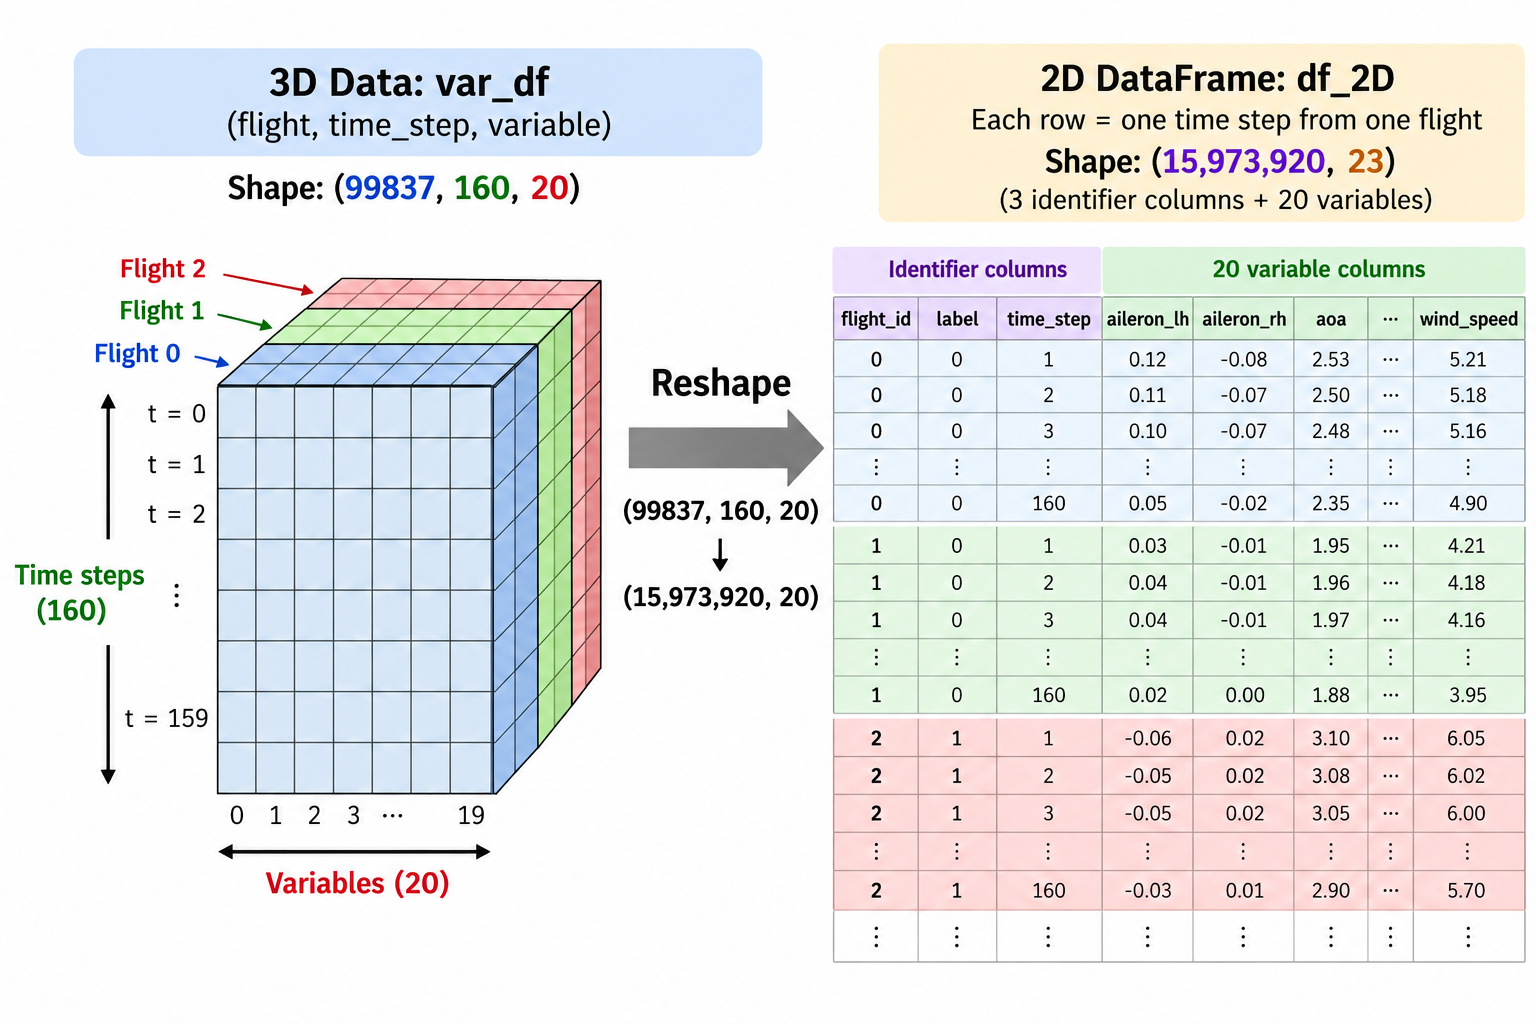

In [ ]:
from IPython.display import Image, display
display(Image("/content/3D-to-2D Data Conversion.png", width=700))


In [ ]:
# Original shape:
n_flights, n_timesteps, n_variables = var_df.shape # (99837, 160, 20)

# Convert var_df from 3D to 2D where each row represents one time step from one flight
var_df_2D=var_df.reshape(-1, n_variables) # 3D(99837, 160, 20) --> [(99837*160, 20)=(15,973,920, 20)]

# Create the DataFrame df_all for the var_df_2D:
# List of variables:
variable_names = ["aileron_lh", "aileron_rh", "aoa", "altitude", "airspeed", "sel_course", "drift_angle", "elevator_l", "flap_pos", "gl_slp_dev", "sel_heading",
    "loc_dev", "core_speed", "tot_pressure", "pitch_angle", "roll_angle", "rudder_pos", "true_heading", "vert_accel", "wind_speed"]

df_2D = pd.DataFrame(var_df_2D, columns=variable_names)

# Add flight_id to df_2D:
df_2D.insert(0, "flight_id", np.repeat(np.arange(n_flights), n_timesteps))

# Add label to df_2D
df_2D.insert(1, "label", np.repeat(label_df, n_timesteps))

# Add time_step to df_2D
df_2D.insert(2, "time_step", np.tile(np.arange(1, n_timesteps + 1), n_flights))

# Show the first 163 rows of df_2D
df_2D.head(163)


,flight_id,label,time_step,aileron_lh,aileron_rh,aoa,altitude,airspeed,sel_course,drift_angle,elevator_l,flap_pos,gl_slp_dev,sel_heading,loc_dev,core_speed,tot_pressure,pitch_angle,roll_angle,rudder_pos,true_heading,vert_accel,wind_speed
0,0,0.0,1,81.261190,82.652336,-8.111792,1969.61740,155.57140,-2.109358,-0.692778,-4.952854,3065.0,0.01794,-2.109358,0.006664,70.741180,985.42550,-3.662261,0.785912,-0.390141,-1.081870,0.972379,12.625183
1,0,0.0,2,79.604095,81.015700,-7.644611,1955.69950,154.51205,-2.109358,-0.867216,-5.198349,3065.0,0.01950,-2.109358,0.007448,70.717750,985.52030,-3.665276,0.046774,-0.756234,-0.704820,0.770077,11.893839
2,0,0.0,3,81.302110,80.770200,-7.552573,1940.02670,153.32867,-2.109358,-1.424093,-4.830105,3065.0,0.01872,-2.109358,0.009604,70.702760,985.41650,-3.940319,0.804820,-1.325632,-0.240446,0.543937,12.559112
3,0,0.0,4,82.345470,83.900276,-8.395265,1924.54930,150.88818,-2.109358,-1.141912,-4.625526,3065.0,0.01677,-2.109358,0.009408,70.741590,984.81710,-4.275129,1.077102,-0.326884,-0.191627,1.062817,10.542998
4,0,0.0,5,81.874930,82.754620,-7.854284,1905.36700,150.69461,-2.109358,-0.724660,-4.400490,3065.0,0.01677,-2.109358,0.009408,70.570450,985.23065,-4.241483,1.654806,0.129545,-0.528425,0.867628,9.713539
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
158,0,0.0,159,83.900276,84.698135,1.317100,335.11508,114.10125,-2.109358,-1.529666,-2.047817,3701.0,-0.16380,-2.109358,-0.005684,79.324840,1024.83230,0.681758,1.592121,-1.356709,0.513559,1.050346,8.270673
159,0,0.0,160,82.570500,77.128680,0.652506,321.76358,114.75626,-2.109358,-0.819070,-1.004459,3701.0,-0.14664,-2.109358,0.003136,79.679760,1025.56470,1.094914,0.962178,-4.275764,0.296197,1.096334,9.127736
160,1,0.0,1,78.110660,78.499360,-6.283905,3301.55620,181.57553,7.997990,-1.273455,-5.873463,2493.0,0.14586,-19.072126,-0.185612,62.359978,958.36140,-3.243135,4.222164,-0.449211,-27.665743,0.886602,7.155745
161,1,0.0,2,78.212950,80.176920,-5.993446,3288.41460,182.20992,7.997990,-2.466920,-5.198349,2493.0,0.15132,-19.072126,-0.162680,62.344135,959.05330,-3.293772,7.655951,-0.720220,-25.975372,0.974667,8.690796


In [ ]:
# The dataset was examined for missing values.
print("=" * 50)
print(f"Total observations:      {len(df_2D):,}")
print(f"Total missing values:    {df_2D.isnull().sum().sum():,}")
print(f"Variables with any NaN:  {(df_2D.isnull().sum() > 0).sum()}")
print("=" * 50)
print("Missing values per variable:")
print(df_2D.isnull().sum()) # No missing values were observed in the dataset.


Total observations:      15,973,920
Total missing values:    0
Variables with any NaN:  0
Missing values per variable:
flight_id       0
label           0
time_step       0
aileron_lh      0
aileron_rh      0
aoa             0
altitude        0
airspeed        0
sel_course      0
drift_angle     0
elevator_l      0
flap_pos        0
gl_slp_dev      0
sel_heading     0
loc_dev         0
core_speed      0
tot_pressure    0
pitch_angle     0
roll_angle      0
rudder_pos      0
true_heading    0
vert_accel      0
wind_speed      0
dtype: int64


# **STEP 2. DATA PREPROCESSING AND FEATURE ENGINEERING**

In [ ]:
# The target variable "label" contains three anomaly classes: # Speed High (1), Path High (2), and Flaps Late Setting (3). ↲
# These classes are combined into a single "Anomalous" class (1), while normal flights (0) remain unchanged, resulting in binary classification.
print(df_2D["label"].value_counts())


label
0.0    14346080
1.0     1122080
2.0      353120
3.0      152640
Name: count, dtype: int64


In [ ]:
# Convert Multiclass Anomaly Labels to Binary Classification (Normal vs. Anomalous)
df_2D["label"] = df_2D["label"].map(lambda x: 1 if x != 0 else 0)
df_2D["label"].value_counts()

print(df_2D["label"].value_counts(), '\n')
print(df_2D["label"].value_counts(normalize=True).round(2))


label
0    14346080
1     1627840
Name: count, dtype: int64 

label
0    0.9
1    0.1
Name: proportion, dtype: float64


### **Exploratory Data Analysis (EDA): Feature Distributions by Anomaly Status Using Boxplots**


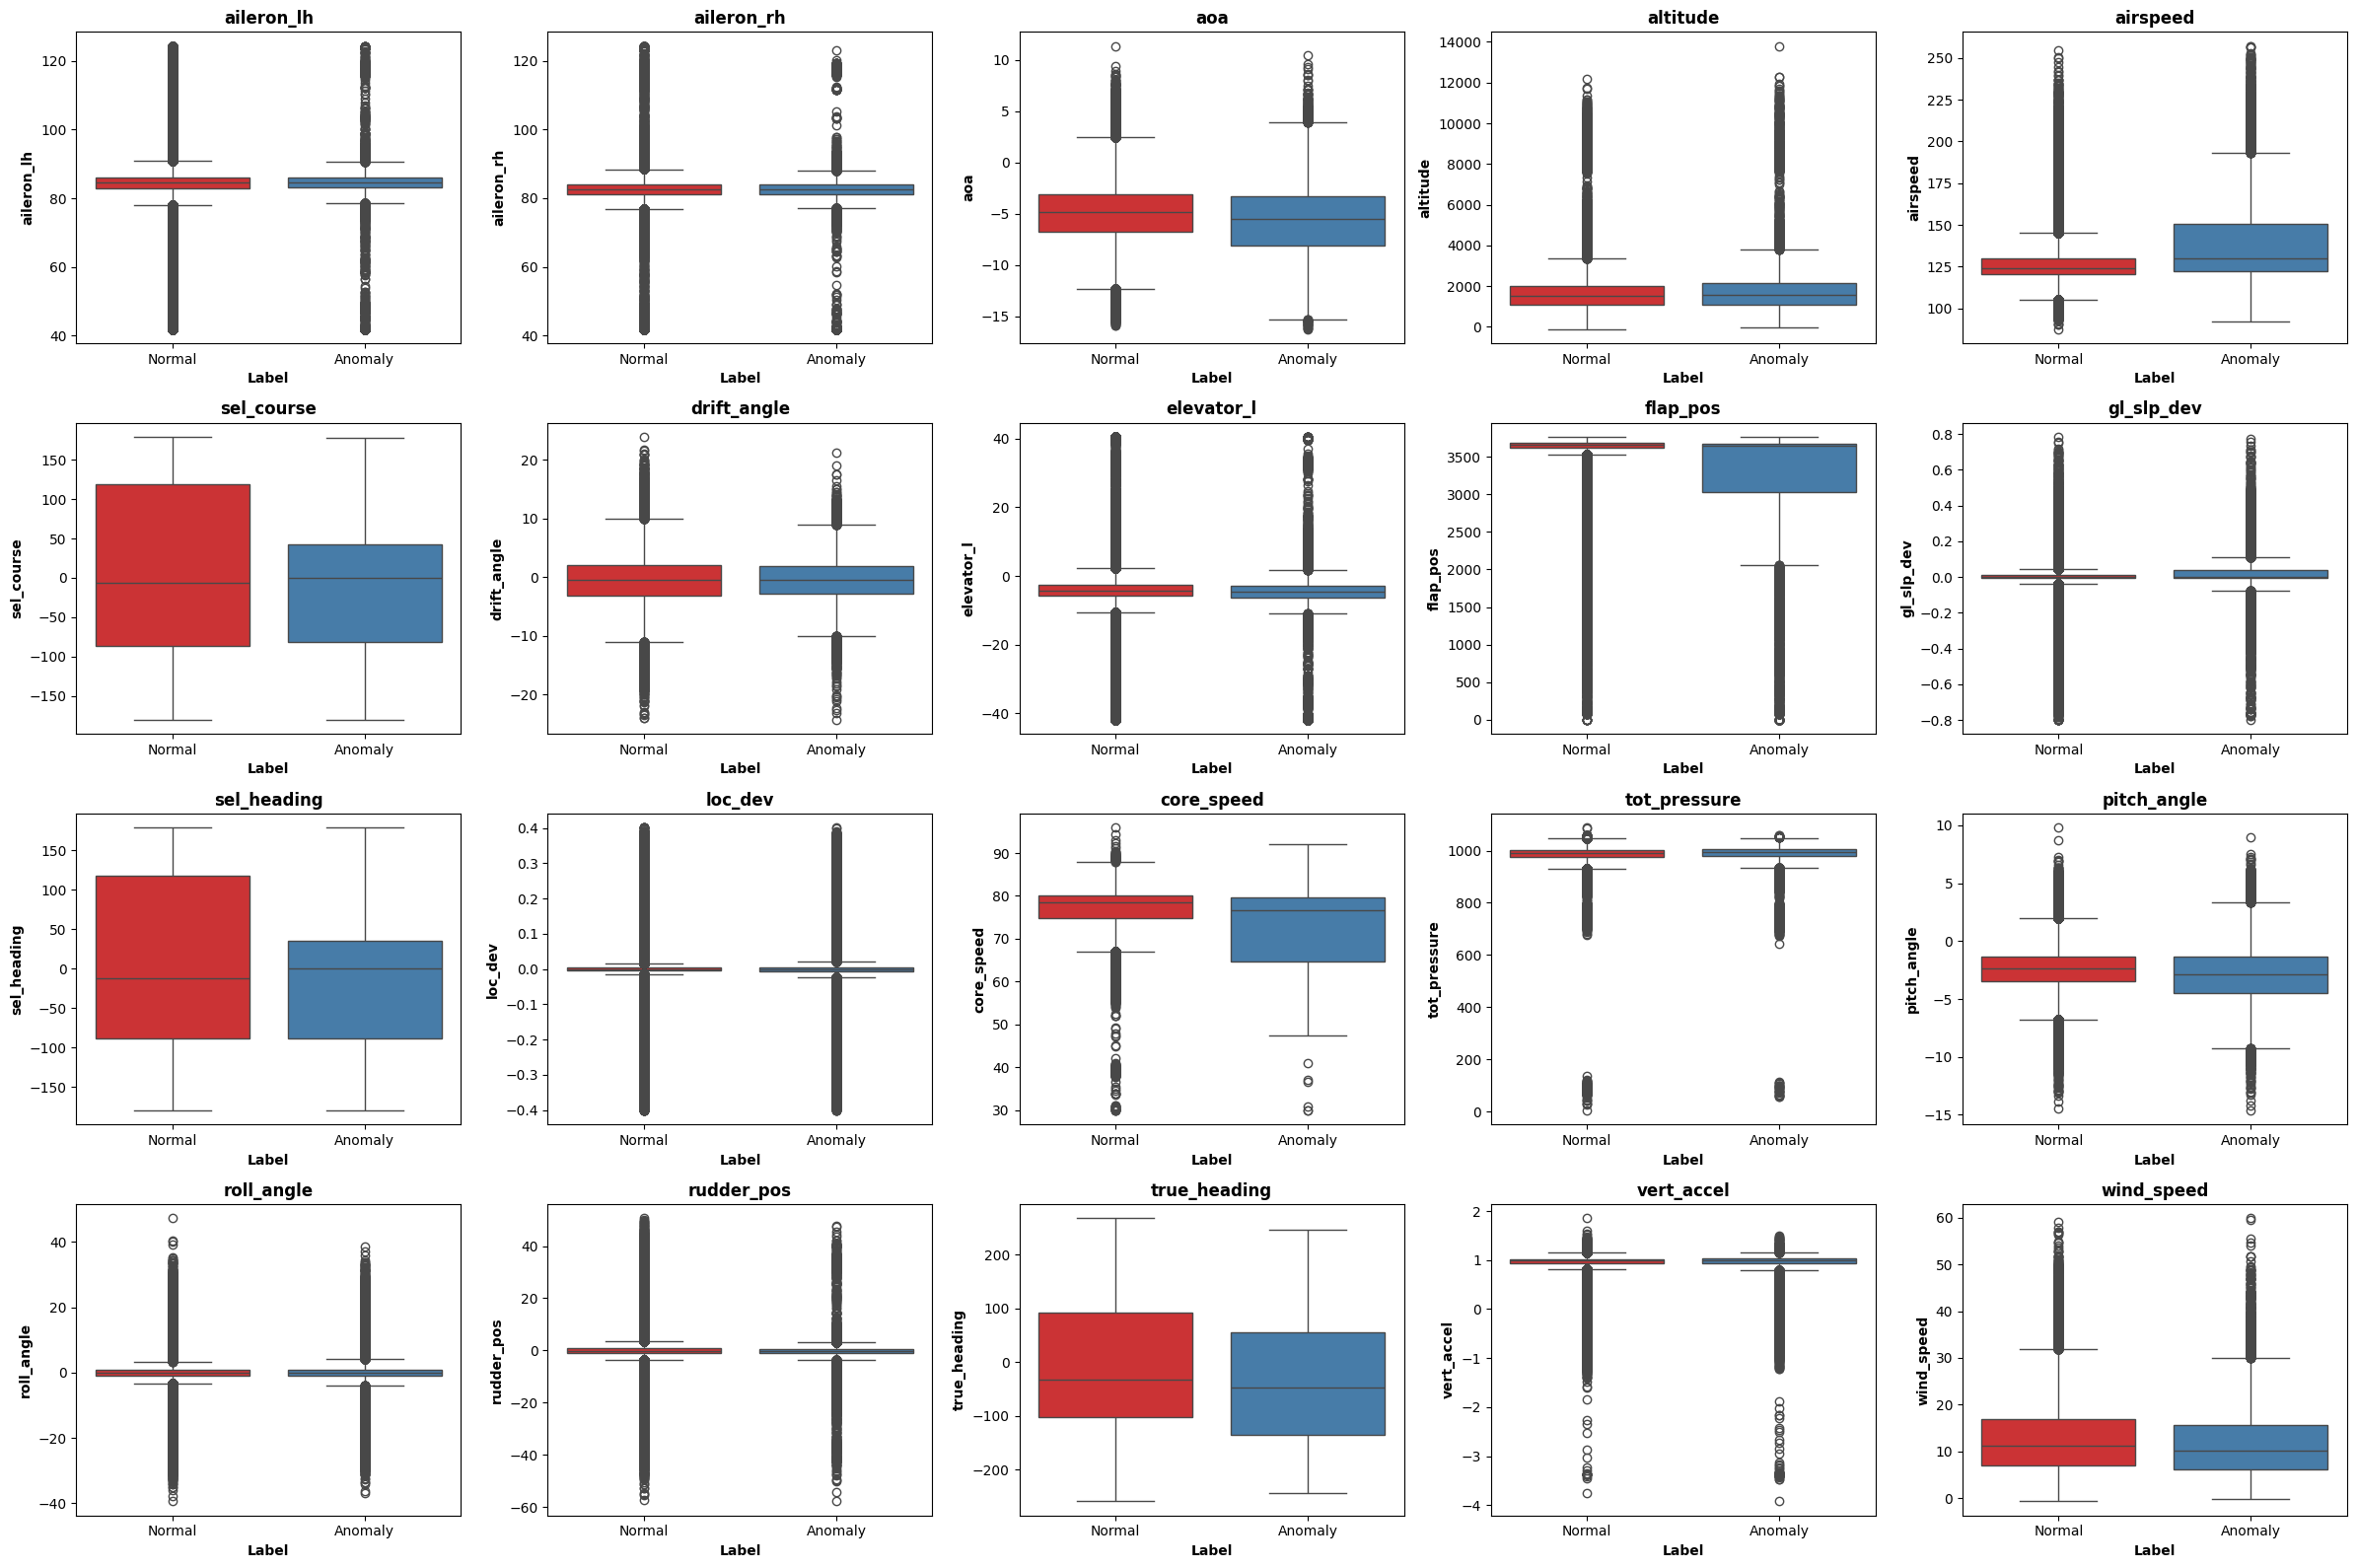

In [ ]:
model_features = df_2D.columns[~df_2D.columns.isin(['flight_id', 'label', 'time_step'])]

# Sample data for faster plotting
plot_df = df_2D.sample(300000, random_state=10)

fig, axes = plt.subplots(4, 5, figsize=(24, 16))
axes = axes.flatten()

for i, feature in enumerate(model_features):
    sns.boxplot(data=plot_df, x="label", y=feature, hue="label", palette="Set1", legend=False,ax=axes[i])
    axes[i].set_title(feature, fontweight="bold")
    axes[i].set_xlabel("Label", fontweight="bold")
    axes[i].set_ylabel(feature, fontweight="bold")
    axes[i].set_xticks([0, 1])
    axes[i].set_xticklabels(["Normal", "Anomaly"])

for j in range(len(model_features), len(axes)):
    axes[j].axis("off")

plt.tight_layout()
plt.show()


### **Evaluation of Feature Aggregation Methods**

To transform the time-series flight data into flight-level features, three aggregation methods were initially evaluated: **mean, standard deviation, and maximum**. The temporal patterns of these statistics were compared between normal and anomalous flights for the selected flight variables. Based on this exploratory analysis, **mean and standard deviation** were retained for feature aggregation, as they provided useful information about both the **overall level** and **variability** of each flight characteristic. The maximum was not included in the final aggregated feature set.

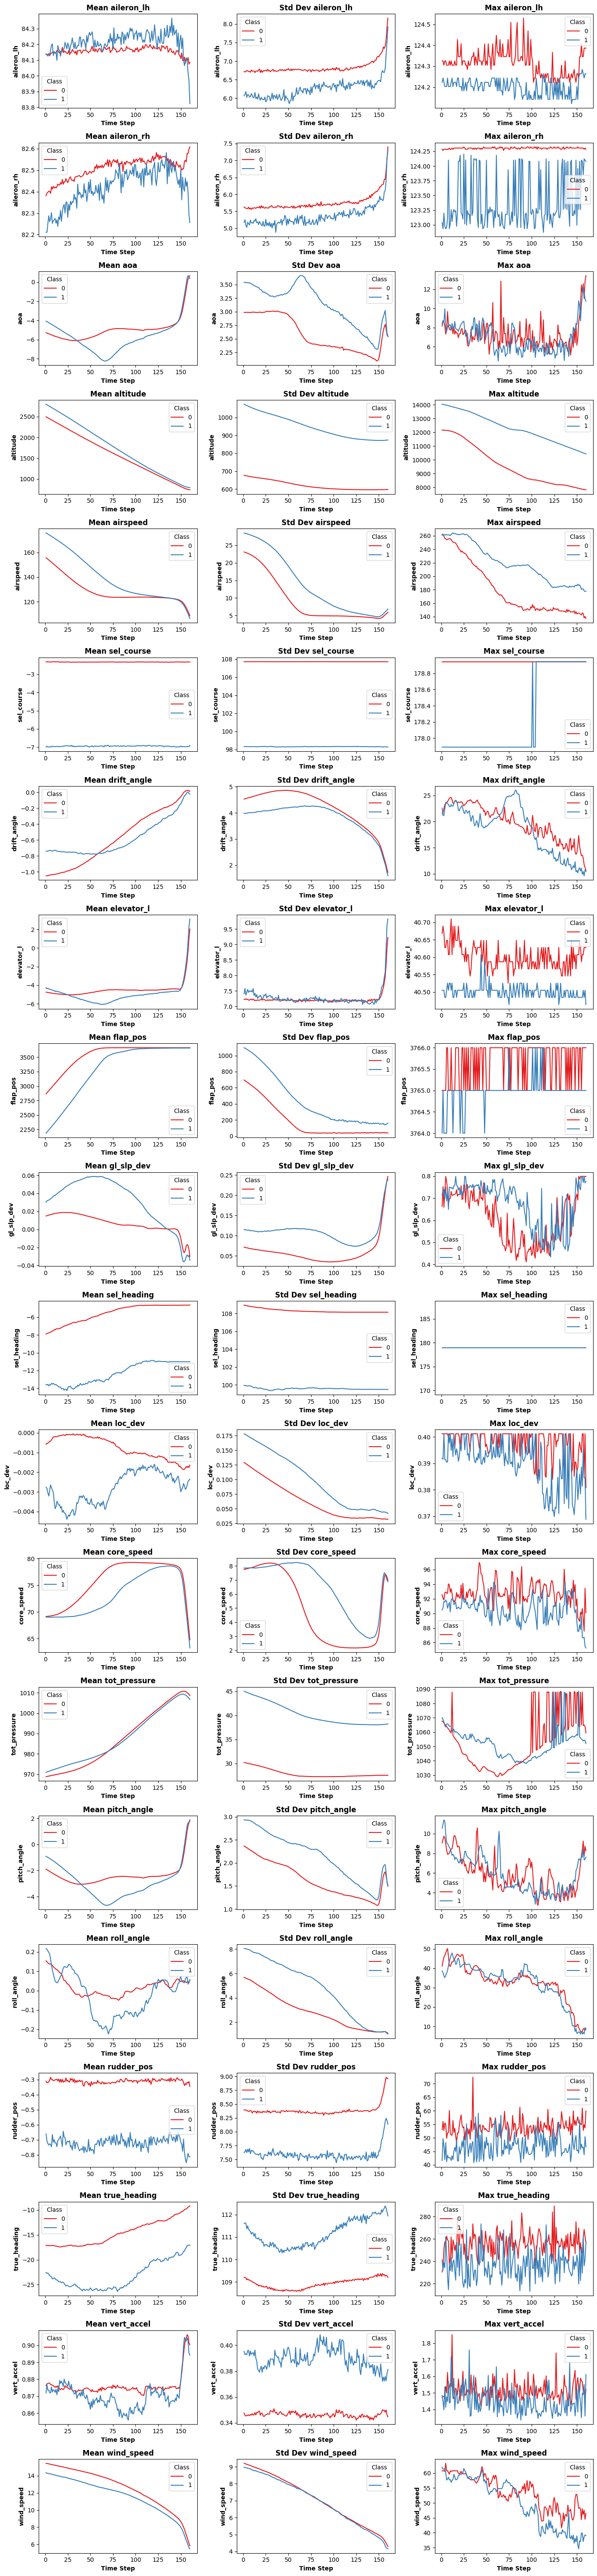

In [ ]:
fig, axes = plt.subplots(nrows=len(model_features), ncols=3, figsize=(14, 3*len(model_features)))
for i, feature in enumerate(model_features):
    # For Mean
    mean_feature = (df_2D.groupby(["time_step", "label"])[feature].mean().reset_index())
    sns.lineplot(data=mean_feature, x="time_step", y=feature, hue="label", palette="Set1", ax=axes[i, 0])
    axes[i, 0].set_title(f"Mean {feature}", fontweight="bold")
    axes[i, 0].set_xlabel("Time Step", fontweight="bold")
    axes[i, 0].set_ylabel(feature, fontweight="bold")
    axes[i, 0].legend(title="Class")

    # For Standard Deviation
    std_feature = (df_2D.groupby(["time_step", "label"])[feature].std().reset_index())
    sns.lineplot(data=std_feature, x="time_step", y=feature, hue="label", palette="Set1", ax=axes[i, 1])
    axes[i, 1].set_title(f"Std Dev {feature}", fontweight="bold")
    axes[i, 1].set_xlabel("Time Step", fontweight="bold")
    axes[i, 1].set_ylabel(feature, fontweight="bold")
    axes[i, 1].legend(title="Class")

    # For Max
    max_feature = (df_2D.groupby(["time_step", "label"])[feature].max().reset_index())
    sns.lineplot(data=max_feature, x="time_step", y=feature, hue="label", palette="Set1", ax=axes[i, 2])
    axes[i, 2].set_title( f"Max {feature}", fontweight="bold")
    axes[i, 2].set_xlabel("Time Step", fontweight="bold")
    axes[i, 2].set_ylabel(feature, fontweight="bold")
    axes[i, 2].legend(title="Class")

plt.tight_layout()
plt.show()


In [ ]:
# Aggregate mean and standard deviation at flight level
df_agg = (df_2D.groupby("flight_id")[model_features].agg(["mean", "std"]))

# Add mean and std suffixes to column names
df_agg.columns = [f"{feature}_{stat}"
    for feature, stat in df_agg.columns]

df_agg = df_agg.reset_index()

# Add flight-level target
target = (df_2D.groupby("flight_id")["label"].first().reset_index())

df_agg = df_agg.merge(target, on="flight_id", how="left")

# As explained in the PROJECT SUMMARY section, "flap_pos_mean" and "flap_pos_std" were removed from df_agg to prevent data leakage.
df_agg.drop(columns=["flap_pos_mean", "flap_pos_std"], axis=1, inplace=True)
df_agg.head()


,flight_id,aileron_lh_mean,aileron_lh_std,aileron_rh_mean,aileron_rh_std,aoa_mean,aoa_std,altitude_mean,altitude_std,airspeed_mean,airspeed_std,sel_course_mean,sel_course_std,drift_angle_mean,drift_angle_std,elevator_l_mean,elevator_l_std,gl_slp_dev_mean,gl_slp_dev_std,sel_heading_mean,sel_heading_std,loc_dev_mean,loc_dev_std,core_speed_mean,core_speed_std,tot_pressure_mean,tot_pressure_std,pitch_angle_mean,pitch_angle_std,roll_angle_mean,roll_angle_std,rudder_pos_mean,rudder_pos_std,true_heading_mean,true_heading_std,vert_accel_mean,vert_accel_std,wind_speed_mean,wind_speed_std,label
0,0,81.266564,1.818805,82.105597,4.912936,-4.565383,2.777340,1102.662484,457.001218,124.692591,9.214812,-2.109358,0.0,-1.209114,0.714210,-3.248447,1.009057,0.001394,0.025232,-2.109358,0.000000,0.002276,0.004258,77.591430,6.353414,1001.762683,13.432021,-1.895558,1.783895,-0.168108,1.204784,-0.706464,0.818808,0.381983,0.896360,0.929766,0.257088,10.789045,2.138787,0
1,1,81.213884,2.253339,82.342654,2.481823,-3.894063,2.952474,1993.313829,665.962731,140.545762,22.163948,7.997990,0.0,-3.521659,1.228081,-5.063455,4.309041,0.080757,0.089431,4.688383,8.777953,0.009061,0.034343,70.653174,8.343218,981.482559,13.640569,-2.310019,1.736269,2.472004,7.710989,-0.989186,1.616086,14.015765,9.604990,0.835092,0.399606,8.938388,2.296485,0
2,2,81.511548,2.052128,82.904738,1.999665,-3.104998,2.701813,1154.263600,531.137231,128.224637,10.725240,-2.109358,0.0,-0.150016,1.411378,-3.684458,1.558324,0.028307,0.051500,-8.903255,11.963090,-0.033397,0.055631,76.165936,8.885065,999.540228,15.304838,-1.778242,1.716118,0.608531,2.192154,-1.409505,3.560667,-3.545832,4.669515,0.898057,0.348977,7.470958,1.715582,0
3,3,81.227437,1.571479,82.597101,1.812453,-3.726846,2.473116,901.706714,467.629577,123.039487,11.448093,165.936330,0.0,-2.409421,0.779628,-0.691325,1.284315,-0.000419,0.013665,165.936330,0.000000,0.004117,0.007157,76.475464,6.500893,1005.061422,13.080918,-1.604656,1.472162,-0.064167,1.248944,-1.583777,3.590585,168.939981,1.234758,0.826536,0.406469,9.038239,1.837372,0
4,4,80.414104,6.249064,82.736598,0.962376,-5.567469,2.418550,1133.942162,479.356100,125.001667,5.171281,-2.109358,0.0,-3.222694,0.800244,-3.676786,3.207752,0.006196,0.031479,-2.109358,0.000000,-0.000940,0.002464,78.692939,5.729938,1000.680496,16.218605,-2.569867,1.416413,-0.468801,0.637306,-0.280463,0.659386,2.333000,0.841506,0.891961,0.329723,9.872985,2.953472,0


### **Integrating Airport and Runway Information into Flight Features**


In [ ]:
# Combine 'arrival_airport' and 'arrival_runway' into a single categorical feature ('arr_arprt_runway') ↲
# to capture airport-specific runway information before merging it with 'df_agg'.
meta_df['arr_arprt_runway']=meta_df["arrival_airport"] + "-" + meta_df["arrival_runway"]
print(meta_df['arrival_airport'].value_counts(), '\n')
print(meta_df['arr_arprt_runway'].value_counts())


arrival_airport
KMSP    25396
KDTW    18797
KMEM     9557
KOKC     2544
KDSM     2367
        ...  
KIDA        1
KLAN        1
KPVU        1
KCPS        1
KCWA        1
Name: count, Length: 97, dtype: int64 

arr_arprt_runway
KMSP-30R    7784
KMSP-12L    7313
KDTW-22R    6223
KDTW-21L    5821
KMSP-30L    5294
            ... 
KSTL-30R       1
KDEN-17R       1
KCPS-30L       1
KGRB-NAN       1
KBTV-19        1
Name: count, Length: 434, dtype: int64


In [ ]:
# Group arrival airports and airport–runway combinations with fewer than ↲
# 10 observations into an "OTHER" category to reduce categorical sparsity.
counts_arr_arpt = meta_df["arrival_airport"].value_counts()
rare_arr_aprt_cat = counts_arr_arpt[counts_arr_arpt.values < 10].index
meta_df["arr_arprt"] = (meta_df["arrival_airport"].where(~meta_df["arrival_airport"].isin(rare_arr_aprt_cat), "OTHER"))
print(meta_df["arr_arprt"].value_counts(), '\n')

counts_arpt_runway = meta_df["arr_arprt_runway"].value_counts()
rare_arr_arpt_runway_cat= counts_arpt_runway[counts_arpt_runway.values < 10].index
meta_df["arr_arprt_rnwy"] = (meta_df["arr_arprt_runway"].where(~meta_df["arr_arprt_runway"].isin(rare_arr_arpt_runway_cat), "OTHER"))
print(meta_df["arr_arprt_rnwy"].value_counts(), '\n')


arr_arprt
KMSP     25396
KDTW     18797
KMEM      9557
KOKC      2544
KDSM      2367
         ...  
KGJT        40
OTHER       35
KHUL        32
KSBN        17
KCTB        12
Name: count, Length: 83, dtype: int64 

arr_arprt_rnwy
KMSP-30R    7784
KMSP-12L    7313
KDTW-22R    6223
KDTW-21L    5821
KMSP-30L    5294
            ... 
KMKE-1L       10
KPHL-9L       10
KATL-9R       10
KJAX-14       10
KICT-1R       10
Name: count, Length: 285, dtype: int64 



In [ ]:
# Merge airport and runway features into the aggregated dataset (df_agg)
df_agg = df_agg.merge(meta_df[["data_instance", "arr_arprt", "arr_arprt_rnwy"]], left_on="flight_id", right_on="data_instance", how="left")
df_agg.drop(columns="data_instance", inplace=True)
df_agg.columns


Index(['flight_id', 'aileron_lh_mean', 'aileron_lh_std', 'aileron_rh_mean',
       'aileron_rh_std', 'aoa_mean', 'aoa_std', 'altitude_mean',
       'altitude_std', 'airspeed_mean', 'airspeed_std', 'sel_course_mean',
       'sel_course_std', 'drift_angle_mean', 'drift_angle_std',
       'elevator_l_mean', 'elevator_l_std', 'gl_slp_dev_mean',
       'gl_slp_dev_std', 'sel_heading_mean', 'sel_heading_std', 'loc_dev_mean',
       'loc_dev_std', 'core_speed_mean', 'core_speed_std', 'tot_pressure_mean',
       'tot_pressure_std', 'pitch_angle_mean', 'pitch_angle_std',
       'roll_angle_mean', 'roll_angle_std', 'rudder_pos_mean',
       'rudder_pos_std', 'true_heading_mean', 'true_heading_std',
       'vert_accel_mean', 'vert_accel_std', 'wind_speed_mean',
       'wind_speed_std', 'label', 'arr_arprt', 'arr_arprt_rnwy'],
      dtype='object')

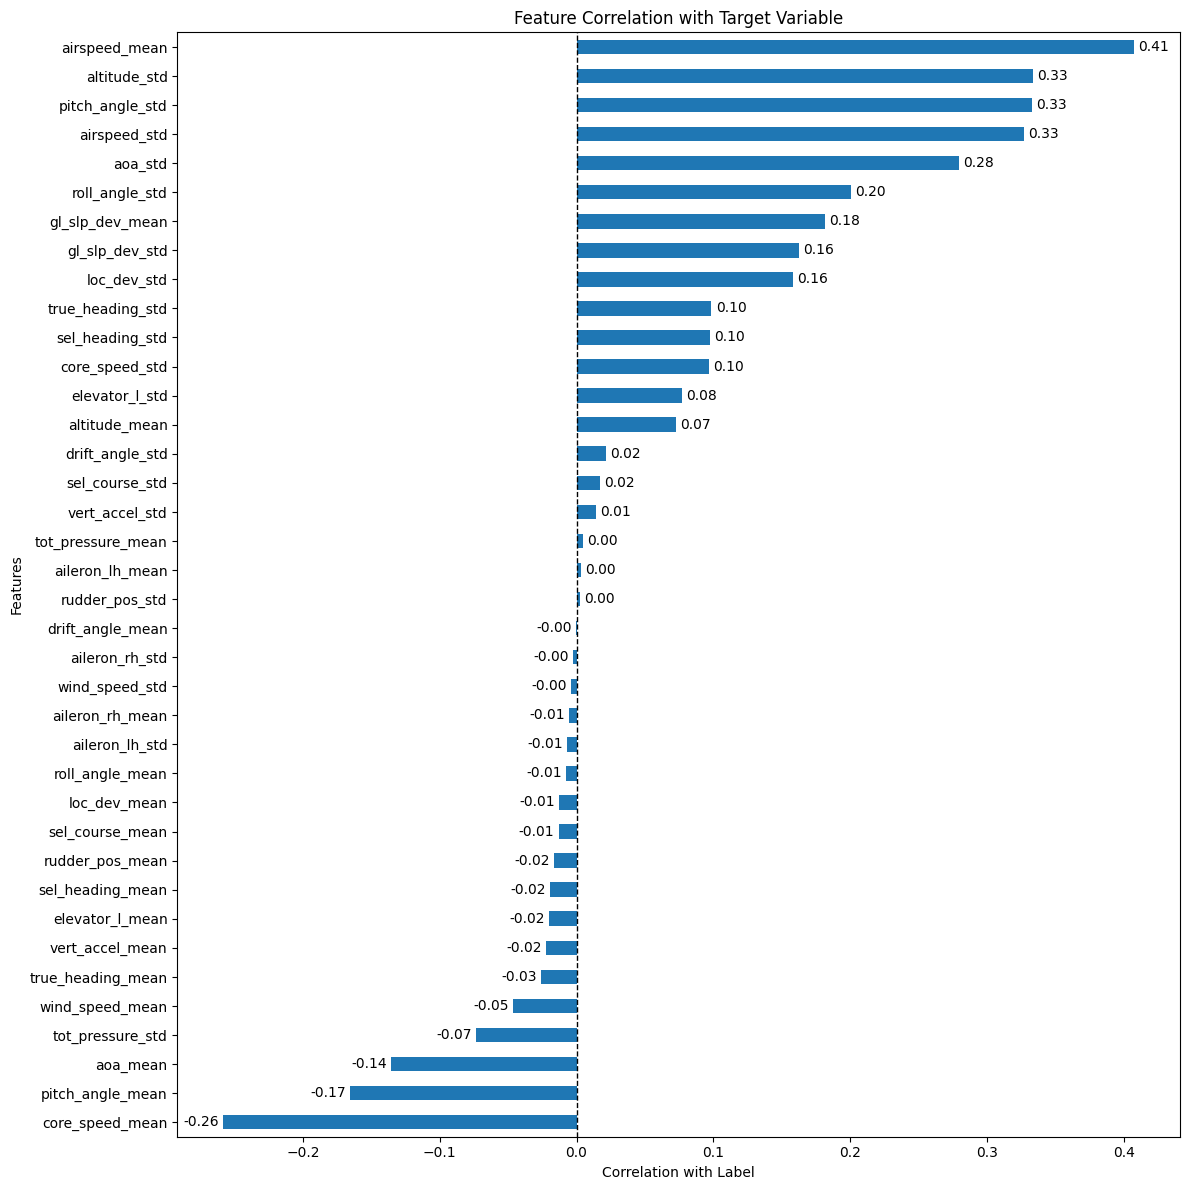

In [ ]:
# Correlation matrix excluding 'arr_arprt', 'arr_arprt_rnwy':
corr_matrix = df_agg.drop(columns=['flight_id', 'arr_arprt', 'arr_arprt_rnwy']).corr()

# Correlation with target
target_corr = corr_matrix['label'].drop('label')

# Sort correlations
target_corr = target_corr.sort_values()

# Plot
plt.figure(figsize=(12, 12))

ax = target_corr.plot(kind='barh')

# Reference line at zero
plt.axvline(x=0, color='black', linestyle='--', linewidth=1)

# Add correlation values to bars
ax.bar_label(ax.containers[0], fmt='%.2f', padding=3)

plt.xlabel('Correlation with Label')
plt.ylabel('Features')
plt.title('Feature Correlation with Target Variable')
plt.tight_layout()
plt.show()


## **Train-Test Split for Model Development & Evaluation**

To develop and evaluate the prediction performance of the alternative models, the dataset was divided into **training (80%)** and **test (20%)** samples, where the former was used to fit the machine learning models, while the latter was used for testing and evaluating the models' prediction accuracy.
This splitting approach helps prevent overfitting and esnures how well the models are expected to perform on unseen data.

In [ ]:
# Split features into the training and test data sets:
X = df_agg.drop(columns=['flight_id', 'label'], axis=1)
Y = df_agg['label']

X_train, X_test, y_train, y_test = train_test_split(X, Y, test_size=0.20, stratify=Y, random_state=10)

print("Shape of training samples:",X_train.shape)
print("Shape of test samples:", X_test.shape)


Shape of training samples: (79869, 40)
Shape of test samples: (19968, 40)


### **Target Encoding of Arrival Airport (arr_arprt) & Arrival Airport Runway (arr_arpt_runway)**
The arr_arprt (N = 83) and arr_arpt_runway features (N = 434) contained a large number of unique categories. Applying one-hot encoding would create many dummy variables, resulting in high dimensionality and sparsity, which can increase computational cost and the risk of overfitting (Galli, S., 2020).

To address this, these two categorical features were transformed using target (mean) encoding. In this approach, each category was replaced with the average target value (anomalous flight rate) associated with that category. To avoid data leakage, the encoding will be based only on the training data, ensuring that no information from the test set influences the training process.


In [ ]:
!pip install category_encoders
import category_encoders as ce

# Initialize Target Encoder
te = ce.TargetEncoder(cols=["arr_arprt", "arr_arprt_rnwy"])

# Fit only on training data
X_train_enc = te.fit_transform(X_train.copy(), y_train)
# Transform test using the same mapping
X_test_enc  = te.transform(X_test.copy())


## **Feature Scaling**  

To ensure comparability across features and improve model performance, this project applied **standardization**, which rescales the input features to have a mean of 0 and a standard deviation of 1. This approach allows the model to assess the relative importance of features on a consistent scale.  

It should be noted that feature scaling was performed **separately for the training and test datasets** to prevent **data leakage**.  


In [ ]:
scaler = StandardScaler()
X_train_scld = scaler.fit_transform(X_train_enc)
X_test_scld  = scaler.transform(X_test_enc)

print("X_train_scld:")
print(X_train_scld)
print()
print("X_test_scld:")
print(X_test_scld)


X_train_scld:
[[-8.08974485e-02 -3.85665097e-01 -3.30107241e-01 ...  9.21840924e-04
   2.13466201e+00  2.03325919e-01]
 [-1.05971916e+00 -8.06661709e-02 -3.91565177e-01 ...  3.10141884e-01
  -1.90308634e-01 -7.21232602e-01]
 [ 1.68242770e-02 -2.39069854e-01  3.10487183e-02 ... -4.09720121e-01
   2.13466201e+00  2.50138579e+00]
 ...
 [ 1.10687303e-01 -1.24327755e-01  2.17157184e-01 ... -5.67065416e-01
  -8.05454980e-01 -5.03618794e-01]
 [ 2.87860440e-01 -2.07815991e-01  4.06654365e-01 ...  6.54581482e-01
  -8.05454980e-01 -5.03618794e-01]
 [ 1.35536182e-01 -4.74671791e-01  3.30692982e-01 ...  1.17149718e+00
  -1.90308634e-01  2.73085556e-01]]

X_test_scld:
[[-0.25400265 -0.02400147  0.07434313 ... -0.55019981 -0.80545498
  -0.50361879]
 [-0.21283597  1.04166704 -0.27214666 ... -0.57370657  0.48286556
   1.32422454]
 [ 0.06587116 -0.17102315  0.0825845  ... -0.39325439 -1.29224
  -1.12667143]
 ...
 [ 0.12282125  0.26809389  2.54374307 ... -0.61966464 -0.80545498
  -0.50361879]
 [ 0.09543

## **Feature Selection**

When developing machine learning models, not all features (predictors) are necessarily associated with the target variable. Including redundant or irrelevant predictors may increase the risk of overfitting and add unnecessary computational complexity. Therefore, feature selection was performed to retain the most relevant predictors before model development.

In this project, **Boruta** was used for feature selection. An **ExtraTreesClassifier** was used as the base estimator because of its ability to efficiently capture nonlinear relationships and interaction effects among predictors. Boruta identifies relevant features by comparing the importance of the original features with that of randomly generated **shadow features**.

Because the target variable (`label`) is highly imbalanced, `class_weight='balanced'` was applied to the ExtraTreesClassifier to give greater consideration to the minority class during the feature-selection process.

Importantly, to avoid **data leakage**, Boruta was fitted using only the training dataset. The selected features were then applied to both the training and test datasets before developing and evaluating the machine learning models.

In [ ]:
!pip install boruta
from boruta import BorutaPy

selector = ExtraTreesClassifier(n_estimators=500, random_state=1, n_jobs=-1, class_weight='balanced')
boruta = BorutaPy(selector, n_estimators='auto', random_state=1)

boruta.fit(X_train_scld, y_train)

selected_features = X_train.columns[boruta.support_]

print()
print("Selected features:", selected_features)
print()
print("Dropped features:", X_train.columns[~boruta.support_], '\n')

# Boolean mask
mask = boruta.support_

# Apply mask
X_train_selected = X_train_scld[:, mask]
X_test_selected  = X_test_scld[:, mask]

print("Shapes after selection:", X_train_selected.shape, X_test_selected.shape, y_train.shape, y_test.shape)



Selected features: Index(['aoa_mean', 'aoa_std', 'altitude_mean', 'altitude_std', 'airspeed_mean',
       'airspeed_std', 'sel_course_mean', 'elevator_l_std', 'gl_slp_dev_mean',
       'gl_slp_dev_std', 'sel_heading_mean', 'sel_heading_std', 'loc_dev_std',
       'core_speed_mean', 'core_speed_std', 'tot_pressure_mean',
       'tot_pressure_std', 'pitch_angle_mean', 'pitch_angle_std',
       'roll_angle_mean', 'roll_angle_std', 'true_heading_mean',
       'true_heading_std', 'wind_speed_mean', 'arr_arprt', 'arr_arprt_rnwy'],
      dtype='object')

Dropped features: Index(['aileron_lh_mean', 'aileron_lh_std', 'aileron_rh_mean',
       'aileron_rh_std', 'sel_course_std', 'drift_angle_mean',
       'drift_angle_std', 'elevator_l_mean', 'loc_dev_mean', 'rudder_pos_mean',
       'rudder_pos_std', 'vert_accel_mean', 'vert_accel_std',
       'wind_speed_std'],
      dtype='object') 

Shapes after selection: (79869, 26) (19968, 26) (79869,) (19968,)


###**Selected & Dropped Features**
**Selected features:**

['aoa_mean', 'aoa_std', 'altitude_mean', 'altitude_std', 'airspeed_mean',
       'airspeed_std', 'sel_course_mean', 'elevator_l_std', 'gl_slp_dev_mean',
       'gl_slp_dev_std', 'sel_heading_mean', 'sel_heading_std', 'loc_dev_std',
       'core_speed_mean', 'core_speed_std', 'tot_pressure_mean',
       'tot_pressure_std', 'pitch_angle_mean', 'pitch_angle_std',
       'roll_angle_mean', 'roll_angle_std', 'true_heading_mean',
       'true_heading_std', 'wind_speed_mean', 'arr_arprt', 'arr_arprt_rnwy']

**Dropped features:**

['aileron_lh_mean', 'aileron_lh_std', 'aileron_rh_mean',
       'aileron_rh_std', 'sel_course_std', 'drift_angle_mean',
       'drift_angle_std', 'elevator_l_mean', 'loc_dev_mean',
       'rudder_pos_mean', 'rudder_pos_std', 'vert_accel_mean',
       'vert_accel_std', 'wind_speed_std']

## **Handling Class Imbalance**

The **anomaly class** represents only about **10%** of all observations in the target variable, resulting in **class imbalance**. Different strategies were adopted depending on the algorithm used.

For **XGBoost** and **Logistic Regression**, two approaches were evaluated. First, the models were trained using the **original training dataset**, with class-imbalance parameters included in the hyperparameter optimization (`scale_pos_weight` for XGBoost and `class_weight` for Logistic Regression). Second, separate models were developed using **SMOTE-resampled training data**. SMOTE (Synthetic Minority Oversampling Technique) generates synthetic minority-class observations to increase the representation of anomalous flights. SMOTE was applied **exclusively to the training data** to prevent data leakage and preserve an unbiased evaluation on the held-out test set.

For **Balanced Random Forest (BRF)**, the original training dataset was used without SMOTE because BRF addresses class imbalance internally through balanced sampling during model training.

For **Isolation Forest** and **Autoencoder**, the original dataset was retained without SMOTE. These anomaly-detection approaches rely on the original data distribution, where anomalies are relatively rare and differ from normal observations. Applying SMOTE would artificially alter this distribution and was therefore not used.

In [ ]:
smote = SMOTE(random_state=100, sampling_strategy='auto')
X_train_smote, y_train_smote = smote.fit_resample(X_train_selected, y_train)
print("Shapes of Training Samples After SMOTE:", X_train_smote.shape, y_train_smote.shape)


Shapes of Training Samples After SMOTE: (143460, 26) (143460,)


# **STEP 3: MACHINE LEARNING MODEL DEVELOPMENT AND EVALUATION**

To detect anomalous flights, six candidate machine learning models were developed and evaluated:

- **Balanced Random Forest (BRF)**
- **Isolation Forest (IF)**
- **XGBoost (XGB)**
- **Autoencoder (AE)**
- **Logistic Regression (LR)**
- **Artificial Neural Network (ANN)**

Each model was developed using the same set of features selected through the **Boruta feature-selection method** and evaluated on the same unseen test dataset. Model performance was assessed using **Recall**, **Precision**, and **F1-score**, with particular emphasis on f1-score due to the class imbalance in the target variable.

Among the candidate models, the **Balanced Random Forest (BRF)** achieved the strongest overall performance across the selected evaluation metrics, including a recall of **0.85** on the test dataset. Based on the comparative evaluation, BRF was selected as the final model for flight anomaly detection.

Detailed development, hyperparameter optimization, and evaluation procedures for each candidate model are presented in the following subsections.


## **(1) Balanced Random Forest Classifier (BRF)**

### **Hyperparameter Optimization**


In [ ]:
# Define hyperparameter grid
param_grid_brf = {
    "n_estimators": [100, 200, 500],
    "max_depth": [3, 5, 7, 10]}

# Balanced Random Forest model
brf = BalancedRandomForestClassifier(random_state=100, n_jobs=-1)

# Randomized search
search_brf = RandomizedSearchCV(estimator=brf, param_distributions=param_grid_brf, n_iter=10, scoring="f1", cv=5, random_state=10, n_jobs=1)

# Fit on original training data, not SMOTE-applied training data
search_brf.fit(X_train_selected, y_train)

# Results
score_brf = pd.DataFrame(search_brf.cv_results_)
scores_brf = score_brf[["params", "mean_test_score", "rank_test_score"]]

print(scores_brf, "\n")

print("Best parameters found:", search_brf.best_params_)
print("Best Cross-Validation F1 Score:", round(search_brf.best_score_, 3))

# Fit best model
brf_optimal = search_brf.best_estimator_

# Predict on test data
y_pred_brf = brf_optimal.predict(X_test_selected)

print("Performance with Tuned Balanced Random Forest:")
print(classification_report(y_test, y_pred_brf))


                                   params  mean_test_score  rank_test_score
0   {'n_estimators': 500, 'max_depth': 3}         0.465982                8
1   {'n_estimators': 100, 'max_depth': 7}         0.622544                3
2   {'n_estimators': 200, 'max_depth': 7}         0.621778                5
3   {'n_estimators': 500, 'max_depth': 5}         0.550520                7
4  {'n_estimators': 500, 'max_depth': 10}         0.659942                1
5   {'n_estimators': 500, 'max_depth': 7}         0.622203                4
6  {'n_estimators': 200, 'max_depth': 10}         0.657223                2
7   {'n_estimators': 100, 'max_depth': 5}         0.556969                6
8   {'n_estimators': 200, 'max_depth': 3}         0.465315                9
9   {'n_estimators': 100, 'max_depth': 3}         0.464649               10 

Best parameters found: {'n_estimators': 500, 'max_depth': 10}
Best Cross-Validation F1 Score: 0.66
Performance with Tuned Balanced Random Forest:
              pr

In [ ]:
# Fit the Balanced Random Forest using the optimal hyperparameters
brf_optimal = BalancedRandomForestClassifier(max_depth=10, n_estimators=500, random_state=10, n_jobs=-1)

brf_optimal.fit(X_train_selected, y_train)

# Predicted probabilities and labels
y_prob_brf = brf_optimal.predict_proba(X_test_selected)[:, 1]
y_pred_brf = brf_optimal.predict(X_test_selected)

# Classification report
print(classification_report(y_test, y_pred_brf))
precision_brf = precision_score(y_test, y_pred_brf)
recall_brf = recall_score(y_test, y_pred_brf)
f1_brf = f1_score(y_test, y_pred_brf)
ap_brf = average_precision_score(y_test, y_prob_brf)
print("Average Precision (AP):", ap_brf.round(3))


              precision    recall  f1-score   support

           0       0.99      0.90      0.94     17933
           1       0.52      0.92      0.66      2035

    accuracy                           0.90     19968
   macro avg       0.75      0.91      0.80     19968
weighted avg       0.94      0.90      0.92     19968

Average Precision (AP): 0.797


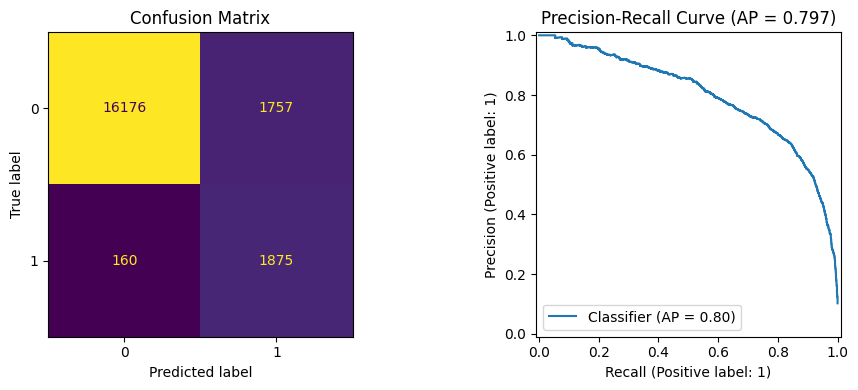

In [ ]:
# Evaluate Model Performance: Confusion Matrix and Precision-Recall Curve
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

# 1. Confusion Matrix
cm_brf = confusion_matrix(y_test, y_pred_brf)

disp_cm_brf = ConfusionMatrixDisplay(confusion_matrix=cm_brf)
disp_cm_brf.plot(ax=axes[0], colorbar=False)
axes[0].set_title("Confusion Matrix")

# 2. Precision-Recall Curve
PrecisionRecallDisplay.from_predictions(y_test, y_prob_brf, ax=axes[1])
axes[1].set_title(f"Precision-Recall Curve (AP = {ap_brf:.3f})")

plt.tight_layout()
plt.show()


## **(2) Isolation Forest**

### **Hyperparameter Optimization**


Based on `y_train.mean()`, anomalies account for approximately **10% of the training observations**. Therefore, `contamination` was included as a **hyperparameter** in the Isolation Forest model and tuned during cross-validation to determine the contamination level that provides the best predictive performance.


In [ ]:
# 1. Define Isolation Forest (Note: I used the observed anomaly rate in the training data as the contamination value.)
iso_forest = IsolationForest(random_state=42, n_jobs=-1)

# 2. Define parameter distributions
param_grid_IF = {
    'contamination': [0.06, 0.08, 0.10, 0.12, 0.15],
    'n_estimators': [100, 200, 500, 1000],
    'max_samples': [128, 256, 512, 1024],
    'max_features': [0.5, 0.75, 1.0]}

# 3. Define custom scoring function

def anomaly_f1_scorer(estimator, X, y):
    # Isolation Forest prediction:
    #  1 = normal
    # -1 = anomaly
    y_pred = estimator.predict(X)

    # Convert to:
    # 0 = normal
    # 1 = anomaly
    y_pred_binary = (y_pred == -1).astype(int)

    return f1_score(y, y_pred_binary)

# 4. RandomizedSearchCV
random_search_IF = RandomizedSearchCV(estimator=iso_forest, param_distributions=param_grid_IF,
                                      n_iter=10, scoring=anomaly_f1_scorer, cv=5, random_state=42, n_jobs=-1)

# 5. Run randomized search
random_search_IF.fit(X_train_selected, y_train)

# 6. Best hyperparameters
print("Best Parameters:")
print(random_search_IF.best_params_)

print("\nBest CV F1 Score:")
print(random_search_IF.best_score_.round(3))


Best Parameters:
{'n_estimators': 200, 'max_samples': 512, 'max_features': 1.0, 'contamination': 0.15}

Best CV F1 Score:
0.36


In [ ]:
# Fit the Isolation Forest using the optimal hyperparameters
IF_optimal = IsolationForest(contamination= 0.15, n_estimators=200, max_samples=512, max_features= 1.0, random_state=10)
IF_optimal.fit(X_train_selected, y_train)

# Predicted probabilities and labels
y_pred_IF = IF_optimal.predict(X_test_selected)
y_pred_binary_IF = (y_pred_IF == -1).astype(int)
print("\nClassification Report:")
print(classification_report(y_test, y_pred_binary_IF))

# Precision, Recall, and F1
precision_IF = precision_score(y_test, y_pred_binary_IF)
recall_IF = recall_score(y_test, y_pred_binary_IF)
f1_IF = f1_score(y_test, y_pred_binary_IF)

# Reverse sign so higher score = more anomalous
y_score_IF = -IF_optimal.decision_function(X_test_selected)

# Average Precision (PR performance)
ap_IF = average_precision_score(y_test, y_score_IF)
print("Average Precision (AP):", round(ap_IF, 3))



Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.88      0.91     17933
           1       0.29      0.44      0.35      2035

    accuracy                           0.83     19968
   macro avg       0.61      0.66      0.63     19968
weighted avg       0.87      0.83      0.85     19968

Average Precision (AP): 0.314


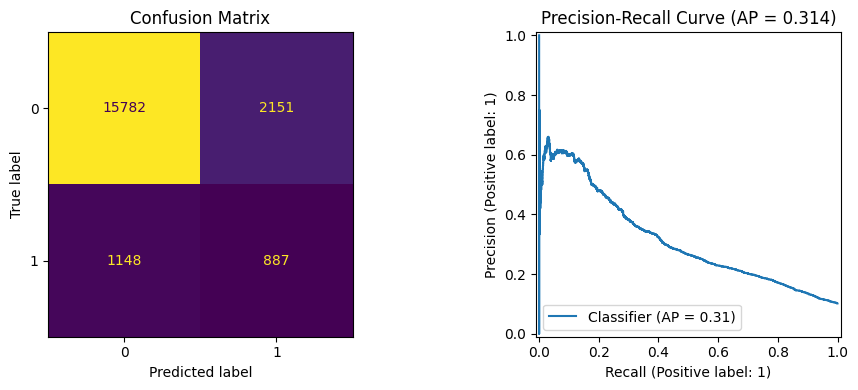

In [ ]:
# Evaluate Model Performance: Confusion Matrix and Precision-Recall Curve
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

# 1. Confusion Matrix
cm_IF = confusion_matrix(y_test, y_pred_binary_IF)
disp_cm_IF = ConfusionMatrixDisplay(confusion_matrix=cm_IF)
disp_cm_IF.plot(ax=axes[0], colorbar=False)
axes[0].set_title("Confusion Matrix")

# 2. Precision-Recall Curve
PrecisionRecallDisplay.from_predictions(y_test, y_score_IF, ax=axes[1])
axes[1].set_title(f"Precision-Recall Curve (AP = {ap_IF:.3f})")

plt.tight_layout()
plt.show()


## **(3) XGBoost Classifier**

Two XGBoost models were developed and compared using two different approaches to address the class imbalance in the dataset:

- **Original Dataset:** XGBoost was trained on the original training data, with `scale_pos_weight` included in the hyperparameter optimization to evaluate class-weight adjustment.
- **SMOTE-Resampled Dataset:** XGBoost was trained using SMOTE-resampled training data to balance the class distribution before model training.

### **(3-1) Hyperparameter Optimization of XGBoost using Original Dataset**


In [ ]:
# Define the hyperparameter grid to search
param_grid_xgb = {'learning_rate': [0.03, 0.50, 0.07, 0.1], 'max_depth': range(4, 15),
                  'n_estimators': [500, 1000, 2000], 'scale_pos_weight': [1, 8.8]} # print(((y_train == 0).sum()/(y_train == 1).sum()))=8.8

# Set up the GridSearchCV
search_xgb = RandomizedSearchCV(estimator=xgb.XGBClassifier(random_state=10),
                                param_distributions=param_grid_xgb, n_iter=10, scoring="f1", cv=5, random_state=10, n_jobs=1)

search_xgb.fit(X_train_selected, y_train)

# Print the cross-validation results
score = pd.DataFrame(search_xgb.cv_results_)
scores = score[['params', 'mean_test_score', 'rank_test_score']]
print(scores,'\n')

# Best parameters:
print("Best Cross-Validation Score:", round(search_xgb.best_score_, 2))

print("Best Parameters:")
print(search_xgb.best_params_)


                                              params  mean_test_score  rank_test_score
0  {'scale_pos_weight': 1, 'n_estimators': 500, '...         0.789429                7
1  {'scale_pos_weight': 1, 'n_estimators': 1000, ...         0.792116                4
2  {'scale_pos_weight': 1, 'n_estimators': 500, '...         0.783206               10
3  {'scale_pos_weight': 1, 'n_estimators': 1000, ...         0.789298                8
4  {'scale_pos_weight': 8.8, 'n_estimators': 1000...         0.785484                9
5  {'scale_pos_weight': 8.8, 'n_estimators': 1000...         0.795918                1
6  {'scale_pos_weight': 1, 'n_estimators': 500, '...         0.791709                5
7  {'scale_pos_weight': 1, 'n_estimators': 2000, ...         0.790365                6
8  {'scale_pos_weight': 8.8, 'n_estimators': 2000...         0.795859                2
9  {'scale_pos_weight': 1, 'n_estimators': 500, '...         0.792574                3 

Best Cross-Validation Score: 0.8
Best Par

In [ ]:
# Fit the XGB Classifier uisng the optimal hyperparameters
xgb_optimal = xgb.XGBClassifier(learning_rate=0.10, max_depth=9, n_estimators=1000, scale_pos_weight=8.8,  random_state=10)
xgb_optimal.fit(X_train_selected, y_train)

# Predicted probabilities and labels
y_prob_xgb = xgb_optimal.predict_proba(X_test_selected)[:, 1]
y_pred_xgb = xgb_optimal.predict(X_test_selected)

# Classification report
print(classification_report(y_test, y_pred_xgb))

precision_xgb = precision_score(y_test, y_pred_xgb)
recall_xgb = recall_score(y_test, y_pred_xgb)
f1_xgb = f1_score(y_test, y_pred_xgb)
ap_xgb = average_precision_score(y_test, y_prob_xgb)
print("Average Precision (AP):", ap_xgb.round(3))


              precision    recall  f1-score   support

           0       0.97      0.98      0.98     17933
           1       0.82      0.76      0.79      2035

    accuracy                           0.96     19968
   macro avg       0.90      0.87      0.88     19968
weighted avg       0.96      0.96      0.96     19968

Average Precision (AP): 0.889


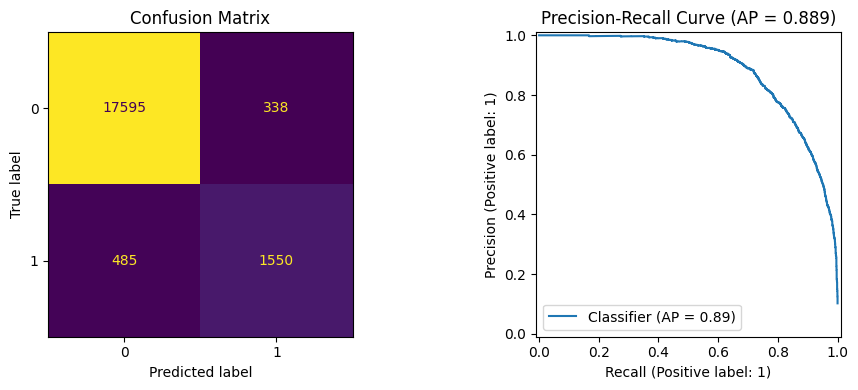

In [ ]:
# Evaluate Model Performance: Confusion Matrix and Precision-Recall Curve
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

# 1. Confusion Matrix
cm_xgb = confusion_matrix(y_test, y_pred_xgb)
disp_cm_xgb = ConfusionMatrixDisplay(confusion_matrix=cm_xgb)
disp_cm_xgb.plot(ax=axes[0], colorbar=False)
axes[0].set_title("Confusion Matrix")

# 2. Precision-Recall Curve
PrecisionRecallDisplay.from_predictions(y_test, y_prob_xgb, ax=axes[1])
axes[1].set_title(f"Precision-Recall Curve (AP = {ap_xgb:.3f})")

plt.tight_layout()
plt.show()


### **(3-2) Hyperparamter tuning of XGBoost using SMOTE-resampled Dataset**

In [ ]:
# 1. Create XGBoost pipeline
pipeline_xgb = Pipeline([('xgb', xgb.XGBClassifier(random_state=10, n_jobs=-1))])


# 2. Define hyperparameter distributions
param_grid_xgb = {
    'xgb__learning_rate': [0.01, 0.03, 0.07, 0.1],
    'xgb__max_depth': range(4, 15),
    'xgb__n_estimators': [200, 500, 1000, 2000]
}


# 3. RandomizedSearchCV
search_xgb = RandomizedSearchCV(estimator=pipeline_xgb, param_distributions=param_grid_xgb, n_iter=10, scoring='f1', cv=5, random_state=10, n_jobs=-1)


# 4. Fit on SMOTE-RESAMPLED training data
search_xgb.fit(X_train_smote, y_train_smote)


# 5. Cross-validation results
score = pd.DataFrame(search_xgb.cv_results_)

scores = score[
    ['params', 'mean_test_score', 'rank_test_score']
].sort_values('rank_test_score')

print(scores, '\n')


# 6. Best parameters and CV score
print("Best Parameters:")
print(search_xgb.best_params_)
print("\nBest Cross-Validation F1 Score:", round(search_xgb.best_score_, 3))

# 7. Get optimal model
xgb_optimal = search_xgb.best_estimator_


                                              params  mean_test_score  rank_test_score
8  {'xgb__n_estimators': 2000, 'xgb__max_depth': ...         0.981482                1
3  {'xgb__n_estimators': 1000, 'xgb__max_depth': ...         0.980828                2
5  {'xgb__n_estimators': 500, 'xgb__max_depth': 1...         0.978402                3
1  {'xgb__n_estimators': 1000, 'xgb__max_depth': ...         0.976911                4
7  {'xgb__n_estimators': 2000, 'xgb__max_depth': ...         0.976496                5
6  {'xgb__n_estimators': 200, 'xgb__max_depth': 1...         0.972357                6
0  {'xgb__n_estimators': 500, 'xgb__max_depth': 1...         0.970703                7
9  {'xgb__n_estimators': 1000, 'xgb__max_depth': ...         0.937057                8
4  {'xgb__n_estimators': 200, 'xgb__max_depth': 7...         0.935567                9
2  {'xgb__n_estimators': 200, 'xgb__max_depth': 9...         0.932028               10 

Best Parameters:
{'xgb__n_estimators': 20

In [ ]:
# Fit the XGB Classifier using the optimal hyperparameters, on the SMOTE-resampled training data
xgb_optimal_SMOTE = xgb.XGBClassifier(learning_rate=0.1, max_depth=9, n_estimators=2000, random_state=10)
xgb_optimal_SMOTE.fit(X_train_smote, y_train_smote)

# Predicted probabilities and labels — evaluated on the ORIGINAL, untouched test set
y_prob_xgb_smote = xgb_optimal_SMOTE.predict_proba(X_test_selected)[:, 1]
y_pred_xgb_smote = xgb_optimal_SMOTE.predict(X_test_selected)

# Classification report
print(classification_report(y_test, y_pred_xgb_smote))

precision_xgb_smote = precision_score(y_test, y_pred_xgb_smote)
recall_xgb_smote = recall_score(y_test, y_pred_xgb_smote)
f1_xgb_smote = f1_score(y_test, y_pred_xgb_smote)
ap_xgb_smote = average_precision_score(y_test, y_prob_xgb_smote)
print("Average Precision (AP):", ap_xgb_smote.round(3))


              precision    recall  f1-score   support

           0       0.98      0.98      0.98     17933
           1       0.78      0.79      0.79      2035

    accuracy                           0.96     19968
   macro avg       0.88      0.88      0.88     19968
weighted avg       0.96      0.96      0.96     19968

Average Precision (AP): 0.882


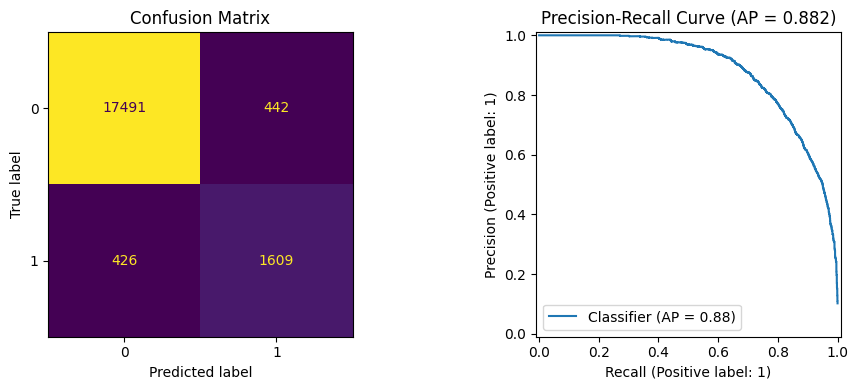

In [ ]:
# Evaluate Model Performance: Confusion Matrix and Precision-Recall Curve
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

# 1. Confusion Matrix
cm_xgb_smote = confusion_matrix(y_test, y_pred_xgb_smote)
disp_cm_xgb_smote = ConfusionMatrixDisplay(confusion_matrix=cm_xgb_smote)
disp_cm_xgb_smote.plot(ax=axes[0], colorbar=False)
axes[0].set_title("Confusion Matrix")

# 2. Precision-Recall Curve
PrecisionRecallDisplay.from_predictions(y_test, y_prob_xgb_smote, ax=axes[1])
axes[1].set_title(f"Precision-Recall Curve (AP = {ap_xgb_smote:.3f})")

plt.tight_layout()
plt.show()


### **Comparison of XGBoost With and Without SMOTE Resampling**

The performance of the **XGBoost model trained on the original imbalanced data** was compared with the **XGBoost model using SMOTE**.

| Class-1 Metric | XGBoost | XGBoost + SMOTE |
|---|---:|---:|
| True Positives (TP) | 1,550 | **1,609** |
| False Negatives (FN) | 485 | **426** |
| False Positives (FP) | **338** | 442 |
| True Negatives (TN) | **17,595** | 17,491 |
| Precision | **0.82** | 0.78 |
| Recall | 0.76 | **0.79** |
| F1-score | **0.79** | **0.79** |
| Average Precision (AP) | **0.889** | 0.882 |

Both models achieved approximately the same **F1-score (0.79)**, indicating a similar overall balance between precision and recall at their respective classification thresholds. However, XGBoost trained on the original dataset with the **optimized class weight** achieved higher **precision (0.82 vs. 0.78)**, fewer **false positives (338 vs. 442)**, and a slightly higher **Average Precision (0.889 vs. 0.882)**. In contrast, the SMOTE-resampled model achieved higher **recall (0.79 vs. 0.76)** and produced fewer false negatives.

Overall, **SMOTE did not improve the overall predictive performance of XGBoost**. Although it increased recall and reduced the number of missed anomalies, this improvement was accompanied by lower precision and substantially more false-positive predictions, while the F1-score remained essentially unchanged. Therefore, **XGBoost trained on the original dataset with the optimized class weight was selected as the preferred XGBoost model**, as it achieved the same F1-score while providing higher precision, fewer false alarms, and slightly higher Average Precision.

## **(4) Autoencoder**

###**Hyperparamter Optimization**

In [ ]:
# 1. Train / validation split
X_train_ae, X_val_selected, y_train_ae, y_val = train_test_split(X_train_selected, y_train, test_size=0.20, stratify=y_train, random_state=10)

# Train AE only on normal observations
X_train_normal = X_train_ae[y_train_ae == 0]

n_features = X_train_selected.shape[1]


In [ ]:
# Hyperparameter Tuning: L2 Regularization and Dropout Rate
results = []

for l2_value in [0.0, 1e-5, 1e-4, 1e-3]:
    for dropout_rate in [0.0, 0.1, 0.2, 0.3]:
        model = keras.Sequential([
            layers.Input(shape=(n_features,)),
            layers.Dense(24, activation="relu", kernel_regularizer=keras.regularizers.l2(l2_value)),
            layers.Dropout(dropout_rate),

            layers.Dense(16, activation="relu", kernel_regularizer=keras.regularizers.l2(l2_value)),
            layers.Dropout(dropout_rate),

            layers.Dense(10, activation="relu", kernel_regularizer=keras.regularizers.l2(l2_value)),

            layers.Dense(16, activation="relu", kernel_regularizer=keras.regularizers.l2(l2_value)),

            layers.Dense(24, activation="relu", kernel_regularizer=keras.regularizers.l2(l2_value)),

            layers.Dense(n_features, activation="linear")])

        model.compile(optimizer="adam", loss="mse")

        early_stopping = EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True)

        history = model.fit(
            X_train_normal,
            X_train_normal,
            epochs=100,
            batch_size=64,
            validation_split=0.20,
            shuffle=True,
            callbacks=[early_stopping],
            verbose=0)

        # Store results
        results.append({
            "L2": l2_value,
            "Dropout": dropout_rate,
            "Best Val Loss": np.min(history.history["val_loss"]),
            "Epochs": len(history.history["loss"])
        })


# Results
df_results = pd.DataFrame(results)
print(df_results)

print("\nBest combination based on validation reconstruction loss:")
best_result = df_results.loc[df_results["Best Val Loss"].idxmin()]

print(best_result)


         L2  Dropout  Best Val Loss  Epochs
0   0.00000      0.0       0.122387     100
1   0.00000      0.1       0.160393     100
2   0.00000      0.2       0.248550      60
3   0.00000      0.3       0.293992      95
4   0.00001      0.0       0.084888     100
5   0.00001      0.1       0.168925      77
6   0.00001      0.2       0.216985     100
7   0.00001      0.3       0.320851      50
8   0.00010      0.0       0.100821     100
9   0.00010      0.1       0.140073      63
10  0.00010      0.2       0.225726     100
11  0.00010      0.3       0.319708      43
12  0.00100      0.0       0.170270     100
13  0.00100      0.1       0.196246     100
14  0.00100      0.2       0.302407      59
15  0.00100      0.3       0.365090      42

Best combination based on validation reconstruction loss:
L2                 0.000010
Dropout            0.000000
Best Val Loss      0.084888
Epochs           100.000000
Name: 4, dtype: float64


In [ ]:
# Fit the Autoencoder Using the Optimal Hyperparameters
# 1. Use only normal observations for AE training
X_train_normal = X_train_ae[y_train_ae == 0]

n_features = X_train_selected.shape[1]

# 2. Best hyperparameters from validation search
best_l2 = 0.00001
best_dropout = 0.0

# 3. Build final Autoencoder
autoencoder_optimal = keras.Sequential([
    layers.Input(shape=(n_features,)),

    layers.Dense(24, activation="relu", kernel_regularizer=keras.regularizers.l2(best_l2)),
    layers.Dropout(best_dropout),

    layers.Dense(16, activation="relu", kernel_regularizer=keras.regularizers.l2(best_l2)),
    layers.Dropout(best_dropout),

    layers.Dense(10, activation="relu", kernel_regularizer=keras.regularizers.l2(best_l2)),

    layers.Dense(16, activation="relu", kernel_regularizer=keras.regularizers.l2(best_l2)),

    layers.Dense(24, activation="relu", kernel_regularizer=keras.regularizers.l2(best_l2)),

    layers.Dense(n_features, activation="linear")])

# 4. Compile
autoencoder_optimal.compile(optimizer="adam", loss="mse")

# 5. Early stopping
early_stopping = EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True)

# 6. Fit final model
history_optimal = autoencoder_optimal.fit(
    X_train_normal,
    X_train_normal,
    epochs=100,
    batch_size=64,
    validation_split=0.20,
    shuffle=True,
    callbacks=[early_stopping],
    verbose=0)

# 7. Reconstruct validation observations
X_val_pred = autoencoder_optimal.predict(X_val_selected, verbose=0)

# 8. Calculate validation reconstruction errors
val_error = np.mean(np.square(X_val_selected - X_val_pred), axis=1)

# 9. Evaluate possible thresholds
precision, recall, thresholds = precision_recall_curve(y_val, val_error)
f1_scores = (2 * precision[:-1] * recall[:-1] /(precision[:-1] + recall[:-1] + 1e-10))

# 10. Select threshold with highest validation F1
best_idx = np.argmax(f1_scores)

optimal_threshold = thresholds[best_idx]

print("Optimal Threshold:", optimal_threshold)
print("Validation F1:", f1_scores[best_idx])


In [ ]:
# Reconstruct validation observations
X_val_pred = autoencoder_optimal.predict(X_val_selected, verbose=0)

# Calculate validation reconstruction errors
val_error = np.mean(np.square(X_val_selected - X_val_pred), axis=1)

# Evaluate possible thresholds
precision, recall, thresholds = precision_recall_curve(y_val, val_error)
f1_scores = (2 * precision[:-1] * recall[:-1] /(precision[:-1] + recall[:-1] + 1e-10))

# Select threshold with highest validation F1
best_idx = np.argmax(f1_scores)

optimal_threshold = thresholds[best_idx]

print("Optimal Threshold:", optimal_threshold)
print("Validation F1:", f1_scores[best_idx])


Optimal Threshold: 0.11891935559396963
Validation F1: 0.3329745245370467


In [ ]:
# Reconstruct test observations
X_test_pred = autoencoder_optimal.predict(X_test_selected,  verbose=0)

# Calculate reconstruction error
test_error = np.mean(np.square(X_test_selected - X_test_pred), axis=1)

# Apply optimized threshold
y_pred_ae = (test_error >= optimal_threshold).astype(int)

print(classification_report(y_test, y_pred_ae, digits=3))

# Performance metrics
precision_ae = precision_score(y_test, y_pred_ae)
recall_ae = recall_score(y_test, y_pred_ae)
f1_ae = f1_score(y_test, y_pred_ae)
ap_ae = average_precision_score(y_test, test_error)
print("Average Precision (AP):", ap_ae.round(3))


              precision    recall  f1-score   support

           0      0.942     0.786     0.857     17933
           1      0.233     0.574     0.332      2035

    accuracy                          0.764     19968
   macro avg      0.588     0.680     0.594     19968
weighted avg      0.870     0.764     0.803     19968

Average Precision (AP): 0.306


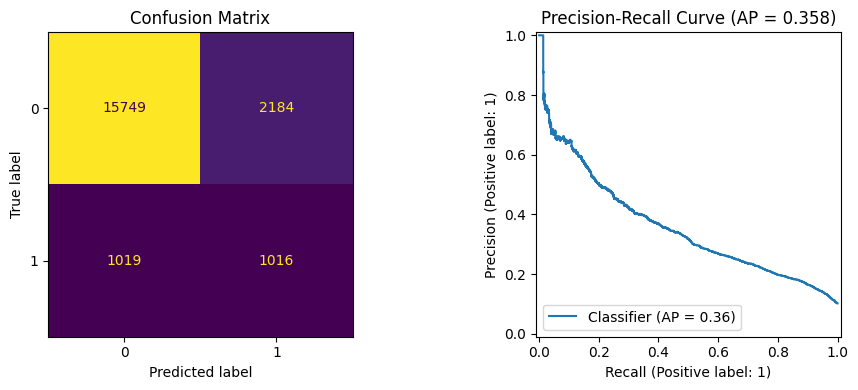

In [ ]:
# Evaluate Model Performance: Confusion Matrix and Precision-Recall Curve
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

# 1. Confusion Matrix
cm_ae = confusion_matrix(y_test, y_pred_ae)
disp_cm_ae = ConfusionMatrixDisplay(confusion_matrix=cm_ae)
disp_cm_ae.plot(ax=axes[0], colorbar=False)
axes[0].set_title("Confusion Matrix")

# 2. Precision-Recall Curve
PrecisionRecallDisplay.from_predictions(y_test, test_error, ax=axes[1])
axes[1].set_title(f"Precision-Recall Curve (AP = {ap_ae:.3f})")

plt.tight_layout()
plt.show()


### **Model Performance of the Balanced Random Forest Classifier (BRF) Model**

The tuned Balanced Random Forest Classifier demonstrated strong and
encouraging performance in detecting flight anomalies on the held-out
test set. The model achieved a **recall of 0.92** for the anomaly class,
correctly identifying **171 out of 191** actual anomalies —
missing only **20 anomalous flights** (false negatives). This high recall
is particularly significant in the context of aviation safety, where
failing to detect a failure or defect carries substantially greater risk
than generating a false alarm. The model's **ROC-AUC of 0.97** further
confirms its strong overall discriminative ability, indicating that the
classifier effectively separates anomalous flights from normal flights
across all possible decision thresholds — as visually confirmed by the
steeply rising ROC curve toward the upper-left corner of the plot.

While the model raised **1,614 false positives** — flagging normal flights
as potential anomalous events — and achieved a precision of **0.54**
for the minority class, this trade-off is considered acceptable and
operationally justifiable given the safety-critical nature of the
application. In aerospace safety analytics, maximizing anomaly detection
rate (recall) takes precedence over minimizing false alarms, as an
undetected failure event poses a significantly greater operational and
safety risk than an unnecessary inspection. The weighted F1-score of **0.91** reflects the model's strong performance on the dominant normal class, though these metrics are acknowledged to be misleading indicators of minority-class performance at this level of class imbalance. Collectively, the recall and AUC results establish the Balanced Random Forest as the most effective model evaluated in this study for the targeted detection of flight anomalies.

## **(5) Logistic Model**
For this section, three different logistic regression models were considered and devleoped:

(A) **Standard logistic model**

(B) **Logistic model with SMOTE-resampled data**

(C) **Multi-level hierarchical logsitic model**

The third model (**multi-level hierarchical logsitic model**) is an advanced extension of standard logistic regression model in which it assumes that flights operating within the same operational environment may share similar characteristics and patterns (Shaheed et al. (2016), Kim et al. (2017)). This model accounts for the hierarchical structure of the data, where flights are nested within arrival runways, and arrival runways are further nested within arrival airports. Consequently, flights operating on the same runway or at the same airport may exhibit correlated characteristics and operational patterns. I have previously applied and published similar spatial prediction models in the context of road crash prediction (see Hosseinpour et al. (2018) and Hosseinpour et al. (2021) for more details). Incorporating such hierarchical or spatial structures into future machine learning frameworks may further improve predictive performance and model interpretability.

###**(5-A) Standard Logistic Model**

In [ ]:
# Define hyperparameter values
param_grid_lr = {
    "C": [0.001, 0.01, 0.1, 1, 10, 100],
    "penalty": ["l1", "l2"],
    "class_weight": [None, "balanced"],
    "solver": ["liblinear"]}

# Initiate logistic regression model
lr = LogisticRegression(max_iter=2000, random_state=10)

# Randomized Search CV for tuning hyperparameters
search_lr = RandomizedSearchCV(estimator=lr, param_distributions=param_grid_lr, n_iter=10, scoring="f1", cv=5, random_state=10, n_jobs=-1)

# Fit on training data
search_lr.fit(X_train_selected, y_train)

# CV results
score_lr = pd.DataFrame(search_lr.cv_results_)

scores_lr = score_lr[["params", "mean_test_score", "rank_test_score"]]

print(scores_lr, "\n")

# Best score
print("Best Cross-Validation F1 Score:", round(search_lr.best_score_, 3))

# Best hyperparameters
print("Best Parameters:")
print(search_lr.best_params_)


                                              params  mean_test_score  rank_test_score
0  {'solver': 'liblinear', 'penalty': 'l2', 'clas...         0.476669                4
1  {'solver': 'liblinear', 'penalty': 'l2', 'clas...         0.433260               10
2  {'solver': 'liblinear', 'penalty': 'l2', 'clas...         0.456641                5
3  {'solver': 'liblinear', 'penalty': 'l1', 'clas...         0.438204                9
4  {'solver': 'liblinear', 'penalty': 'l2', 'clas...         0.454556                6
5  {'solver': 'liblinear', 'penalty': 'l1', 'clas...         0.483820                2
6  {'solver': 'liblinear', 'penalty': 'l2', 'clas...         0.483615                3
7  {'solver': 'liblinear', 'penalty': 'l2', 'clas...         0.483828                1
8  {'solver': 'liblinear', 'penalty': 'l1', 'clas...         0.454043                7
9  {'solver': 'liblinear', 'penalty': 'l2', 'clas...         0.447633                8 

Best Cross-Validation F1 Score: 0.484
Bes

In [ ]:
# Fit the Logistic model using the optimal hyperparameters
lr_optimal = LogisticRegression(solver='liblinear', penalty='l2', class_weight=None, C=1.0, max_iter=2000, random_state=10)
lr_optimal.fit(X_train_selected, y_train)

# Predicted probabilities and labels
y_prob_lr = lr_optimal.predict_proba(X_test_selected)[:, 1]
y_pred_lr = lr_optimal.predict(X_test_selected)

# Classification report
print(classification_report(y_test, y_pred_lr))

# Performance metrics
precision_lr = precision_score(y_test, y_pred_lr)
recall_lr = recall_score(y_test, y_pred_lr)
f1_lr = f1_score(y_test, y_pred_lr)
ap_lr = average_precision_score(y_test, y_prob_lr)
print("Average Precision (AP):", ap_lr.round(3))


              precision    recall  f1-score   support

           0       0.93      0.99      0.96     17933
           1       0.77      0.34      0.47      2035

    accuracy                           0.92     19968
   macro avg       0.85      0.66      0.71     19968
weighted avg       0.91      0.92      0.91     19968

Average Precision (AP): 0.587


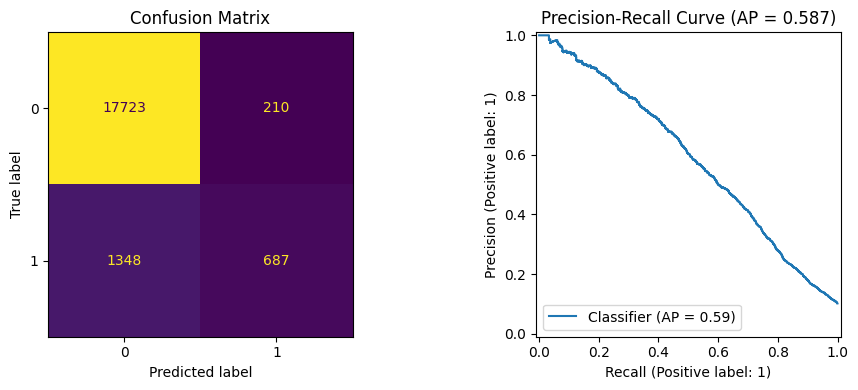

In [ ]:
# Evaluate Model Performance: Confusion Matrix and Precision-Recall Curve
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

# Confusion Matrix
cm_lr = confusion_matrix(y_test, y_pred_lr)
disp_cm_lr = ConfusionMatrixDisplay(confusion_matrix=cm_lr)
disp_cm_lr.plot(ax=axes[0], colorbar=False)
axes[0].set_title("Confusion Matrix")

# Precision-Recall Curve
PrecisionRecallDisplay.from_predictions(y_test, y_prob_lr, ax=axes[1])
axes[1].set_title(f"Precision-Recall Curve (AP = {ap_lr:.3f})")

plt.tight_layout()
plt.show()


###**(5-B) Standard Logistic Model with SMOTE-Resamples Data**

In [ ]:
# Define hyperparameter values
param_grid_lr_smote = {"C": [0.001, 0.01, 0.1, 1, 10, 100], "penalty": ["l1", "l2"], "solver": ["liblinear"]}

# Randomized Search CV
lr=LogisticRegression(max_iter=2000, random_state=10)

search_lr_smote = RandomizedSearchCV(estimator=lr, param_distributions=param_grid_lr_smote, n_iter=10, scoring="f1", cv=5, random_state=10, n_jobs=-1)

# Fit using SMOTE-resampled training data
search_lr_smote.fit(X_train_smote, y_train_smote)

# CV results
score_lr_smote = pd.DataFrame(search_lr_smote.cv_results_)

scores_lr_smote = score_lr_smote[["params", "mean_test_score", "rank_test_score"]].sort_values("rank_test_score")
print(scores_lr_smote, "\n")

# Best CV score
print("Best Cross-Validation F1 Score:", round(search_lr_smote.best_score_, 3))

# Best hyperparameters
print("Best Parameters:")
print(search_lr_smote.best_params_)


                                              params  mean_test_score  rank_test_score
8  {'solver': 'liblinear', 'penalty': 'l2', 'C': ...         0.792331                1
7  {'solver': 'liblinear', 'penalty': 'l2', 'C': ...         0.792022                2
0  {'solver': 'liblinear', 'penalty': 'l1', 'C': ...         0.791520                3
3  {'solver': 'liblinear', 'penalty': 'l2', 'C': ...         0.790476                4
1   {'solver': 'liblinear', 'penalty': 'l1', 'C': 1}         0.790464                5
6  {'solver': 'liblinear', 'penalty': 'l1', 'C': ...         0.790379                6
2   {'solver': 'liblinear', 'penalty': 'l2', 'C': 1}         0.790376                7
5  {'solver': 'liblinear', 'penalty': 'l1', 'C': 10}         0.790373                8
4  {'solver': 'liblinear', 'penalty': 'l2', 'C': ...         0.790325                9
9  {'solver': 'liblinear', 'penalty': 'l1', 'C': ...         0.788595               10 

Best Cross-Validation F1 Score: 0.792
Bes

In [ ]:
# Fit the Logistic model using the optimal hyperparameters on the SMOTE-resampled training data
lr_smote_optimal_smote = LogisticRegression(solver='liblinear', penalty='l2', C=0.001, max_iter=2000, random_state=10)
lr_smote_optimal_smote.fit(X_train_selected, y_train)

# Predicted probabilities and labels on the ORIGINAL test set
y_prob_lr_smote = lr_smote_optimal_smote.predict_proba(X_test_selected)[:, 1]
y_pred_lr_smote = lr_smote_optimal_smote.predict(X_test_selected)

# Classification report
print(classification_report(y_test, y_pred_lr_smote))

# Performance metrics
precision_lr_smote = precision_score(y_test, y_pred_lr_smote)
recall_lr_smote = recall_score(y_test, y_pred_lr_smote)
f1_lr_smote = f1_score(y_test, y_pred_lr_smote)

# Average Precision
ap_lr_smote = average_precision_score(y_test, y_prob_lr_smote)
print("Average Precision (AP):", round(ap_lr_smote, 3))


              precision    recall  f1-score   support

           0       0.92      0.99      0.96     17933
           1       0.77      0.29      0.42      2035

    accuracy                           0.92     19968
   macro avg       0.85      0.64      0.69     19968
weighted avg       0.91      0.92      0.90     19968

Average Precision (AP): 0.584


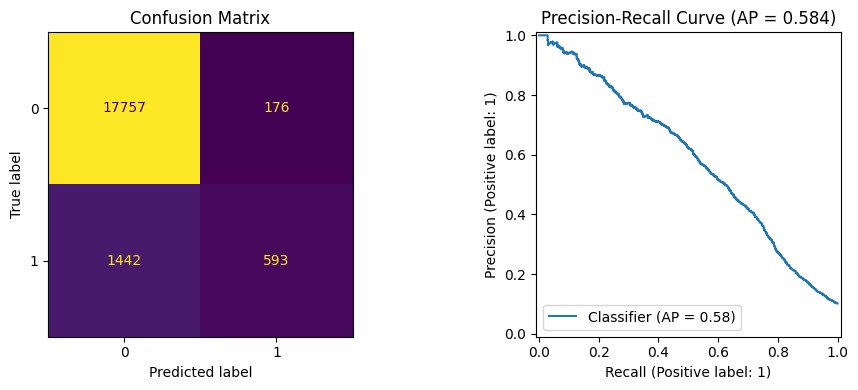

In [ ]:
# Evaluate Model Performance: Confusion Matrix and Precision-Recall Curve
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

# Confusion Matrix
cm_lr_smote = confusion_matrix(y_test, y_pred_lr_smote)
disp_cm_lr_smote = ConfusionMatrixDisplay(confusion_matrix=cm_lr_smote)
disp_cm_lr_smote.plot(ax=axes[0], colorbar=False)
axes[0].set_title("Confusion Matrix")

# Precision-Recall Curve
PrecisionRecallDisplay.from_predictions(y_test, y_prob_lr_smote, ax=axes[1])
axes[1].set_title(f"Precision-Recall Curve (AP = {ap_lr_smote:.3f})")

plt.tight_layout()
plt.show()


###**(5-C) Multi-level hierarchical logsitic model**
The multilevel hierarchical logistic regression model was developed using the statsmodels library to account for the nested structure of flights within arrival runways and airports. However, the model failed to converge and was therefore excluded from the final analysis.

### **Comparison of Logistic Regression Models With and Without SMOTE Resampling**

| Class-1 Metric | LR without SMOTE | LR + SMOTE |
|---|---:|---:|
| True Positives (TP) | **687** | 593 |
| False Negatives (FN) | **1,348** | 1,442 |
| False Positives (FP) | 210 | **176** |
| True Negatives (TN) | 17,723 | **17,757** |
| Recall | **0.34** | 0.29 |
| Precision | **0.77** | **0.77** |
| F1-score | **0.47** | 0.42 |
| Average Precision (AP) | **0.587** | 0.584 |

The application of **SMOTE did not improve the ability of Logistic Regression to detect anomalous flights**. Recall decreased from **0.34 to 0.29**, meaning that the SMOTE-resampled model detected approximately **29% of anomalous flights**, compared with approximately **34%** for Logistic Regression trained on the original dataset. Consequently, the number of missed anomalies increased from **1,348 to 1,442**, corresponding to **94 additional anomalous flights being missed**.

SMOTE reduced the number of false-positive predictions from **210 to 176**. However, class-1 precision remained approximately **0.77** for both models when rounded to two decimal places. Therefore, the reduction in false positives did not compensate for the substantial reduction in correctly detected anomalous flights.

The F1-score decreased from **0.47 without SMOTE to 0.42 with SMOTE**, indicating a poorer balance between precision and recall after SMOTE resampling. Average Precision also decreased slightly from **0.587 to 0.584**, suggesting essentially similar overall ranking performance, with a small advantage for the model trained on the original dataset.

Overall, **SMOTE did not improve Logistic Regression performance in this experiment**. Although it reduced the number of false-positive predictions, it resulted in lower recall, more missed anomalies, and a lower F1-score. Therefore, based on **F1-score as the primary model-selection criterion, Logistic Regression trained on the original dataset is selected over Logistic Regression with SMOTE**.

##**(6) NN Model**

In [ ]:
# Steps to fit optimal hyperparamters () of the NN model:
# 1. Split training data into train and validation sets
X_train2, X_val, y_train2, y_val = train_test_split(X_train_selected, y_train, test_size=0.20, stratify=y_train, random_state=10)

# 2. Hyperparameter tuning
results = []

for reg_value in [0.0, 0.001, 0.01, 0.1]:
    for dropout_rate in [0, 0.1, 0.3, 0.5]:
        model = keras.Sequential([
            layers.Input(shape=(X_train_selected.shape[1],)),
            # Hidden Layer 1
            layers.Dense(200, use_bias=False, kernel_regularizer=keras.regularizers.l2(reg_value)),
            layers.BatchNormalization(),
            layers.Activation("relu"),
            layers.Dropout(dropout_rate),

            # Hidden Layer 2
            layers.Dense(100, use_bias=False, kernel_regularizer=keras.regularizers.l2(reg_value)),
            layers.BatchNormalization(),
            layers.Activation("relu"),
            layers.Dropout(dropout_rate),

            # Hidden Layer 3
            layers.Dense(50, use_bias=False, kernel_regularizer=keras.regularizers.l2(reg_value)),
            layers.BatchNormalization(),
            layers.Activation("relu"),
            layers.Dropout(dropout_rate),

            # Hidden Layer 4
            layers.Dense(25, use_bias=False, kernel_regularizer=keras.regularizers.l2(reg_value)),
            layers.BatchNormalization(),
            layers.Activation("relu"),
            layers.Dropout(dropout_rate),

            # Binary classification output
            layers.Dense(1, activation="sigmoid")])


        # 3. Compile
        model.compile(optimizer="adam", loss="binary_crossentropy", metrics=[keras.metrics.AUC(curve="PR", name="pr_auc"),
                keras.metrics.Precision(name="precision"),
                keras.metrics.Recall(name="recall")])


        # 4. Early stopping
        early_stopping = EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True)


        # 5. Train
        history = model.fit(X_train2, y_train2, validation_data=(X_val, y_val), epochs=200, batch_size=64, callbacks=[early_stopping], verbose=0)


        # 6. Predict validation probabilities/classes
        y_val_prob = model.predict(X_val, verbose=0).ravel()
        y_val_pred = (y_val_prob >= 0.5).astype(int)


        # 7. Calculate validation metrics
        val_loss = model.evaluate(X_val, y_val, verbose=0)[0]

        # Average Precision
        val_ap = average_precision_score(y_val, y_val_prob)

        # F1-score
        val_f1 = f1_score(y_val, y_val_pred)


        # 8. Store results
        results.append({
            "Regularizer Value": reg_value,
            "Dropout Rate": dropout_rate,
            "val_loss": val_loss,
            "val_ap": val_ap,
            "val_f1": val_f1})


results_df = pd.DataFrame(results)
print(results_df)

# Find the best combination based on validation F1-score
best_result = results_df.loc[results_df["val_f1"].idxmax()]

# Extract optimal parameters
optimal_reg_value = best_result["Regularizer Value"]
optimal_dropout_rate = best_result["Dropout Rate"]

print("\nOptimal Hyperparameters:")
print("L2 Regularization:", optimal_reg_value)
print("Dropout Rate:", optimal_dropout_rate)
print("Validation F1:", round(best_result["val_f1"], 3))
print("Validation AP:", round(best_result["val_ap"], 3))


    Regularizer Value  Dropout Rate  val_loss    val_ap    val_f1
0               0.000           0.0  0.112875  0.867642  0.778100
1               0.000           0.1  0.106990  0.884288  0.799202
2               0.000           0.3  0.104886  0.885926  0.789120
3               0.000           0.5  0.109514  0.876122  0.778610
4               0.001           0.0  0.120323  0.878841  0.788923
5               0.001           0.1  0.135913  0.858149  0.778989
6               0.001           0.3  0.151567  0.833514  0.756617
7               0.001           0.5  0.166674  0.815326  0.707581
8               0.010           0.0  0.142555  0.834174  0.748585
9               0.010           0.1  0.157177  0.819739  0.699782
10              0.010           0.3  0.175611  0.782168  0.701706
11              0.010           0.5  0.205635  0.713997  0.508985
12              0.100           0.0  0.160265  0.790325  0.699430
13              0.100           0.1  0.194671  0.697789  0.560624
14        

In [ ]:
# fit the NN model using the optimal hyperparamter values
optimal_reg_value = 0.0
optimal_dropout_rate = 0.1

model_NN_optimal = keras.Sequential([layers.Input(shape=(X_train_selected.shape[1],)),
    # Hidden Layer 1
    layers.Dense(200, use_bias=False, kernel_regularizer=keras.regularizers.l2(optimal_reg_value)),
    layers.BatchNormalization(),
    layers.Activation('relu'),
    layers.Dropout(optimal_dropout_rate),

    # Hidden Layer 2
    layers.Dense(100, use_bias=False, kernel_regularizer=keras.regularizers.l2(optimal_reg_value)),
    layers.BatchNormalization(),
    layers.Activation('relu'),
    layers.Dropout(optimal_dropout_rate),

    # Hidden Layer 3
    layers.Dense(50, use_bias=False, kernel_regularizer=keras.regularizers.l2(optimal_reg_value)),
    layers.BatchNormalization(),
    layers.Activation('relu'),
    layers.Dropout(optimal_dropout_rate),

    # Hidden Layer 4
    layers.Dense(25, use_bias=False, kernel_regularizer=keras.regularizers.l2(optimal_reg_value)),
    layers.BatchNormalization(),
    layers.Activation('relu'),
    layers.Dropout(optimal_dropout_rate),

    # Binary classification output
    layers.Dense(1, activation='sigmoid')])

# Compile
model_NN_optimal.compile(loss='binary_crossentropy', optimizer='adam')

# Train
model_NN_optimal.fit(X_train_selected, y_train, epochs=200, batch_size=64, verbose=0)


Classification Report:
              precision    recall  f1-score   support

           0       0.97      0.98      0.98     17933
           1       0.84      0.74      0.78      2035

    accuracy                           0.96     19968
   macro avg       0.90      0.86      0.88     19968
weighted avg       0.96      0.96      0.96     19968

Average Precision (AP): 0.867 



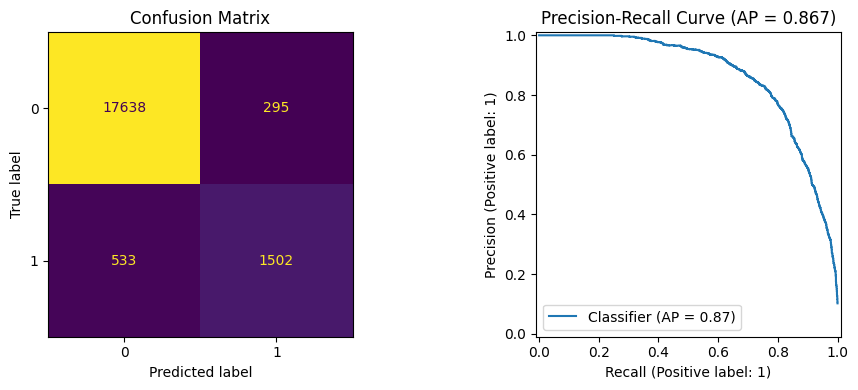

In [ ]:
# Predict probabilities
y_prob_nn = model_NN_optimal.predict(X_test_selected, verbose=0).flatten()

# Convert probabilities to binary predictions
y_pred_nn = (y_prob_nn >= 0.5).astype(int)

# Classification Report
print("Classification Report:")
print(classification_report(y_test, y_pred_nn))

precision_nn = precision_score(y_test, y_pred_nn)
recall_nn = recall_score(y_test, y_pred_nn)
f1_nn = f1_score(y_test, y_pred_nn)
ap_nn = average_precision_score(y_test, y_prob_nn)
print("Average Precision (AP):", ap_nn.round(3), '\n')

# Evaluate Model Performance: Confusion Matrix and Precision-Recall Curve
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

# Confusion Matrix
cm_nn = confusion_matrix(y_test, y_pred_nn)
disp_cm_nn = ConfusionMatrixDisplay(confusion_matrix=cm_nn)
disp_cm_nn.plot(ax=axes[0], colorbar=False)
axes[0].set_title("Confusion Matrix")

# Precision-Recall Curve
PrecisionRecallDisplay.from_predictions(y_test, y_prob_nn, ax=axes[1])
axes[1].set_title(f"Precision-Recall Curve (AP = {ap_nn:.3f})")

plt.tight_layout()
plt.show()


# **STEP 4: MODEL COMPARISON & SELECTION**


In [ ]:
results = {"Balanced Random Forest": {"Precision": precision_brf, "Recall": recall_brf, "F1-score": f1_brf},
    "Isolation Forest": {"Precision": precision_IF, "Recall": recall_IF, "F1-score": f1_IF},
    "XGBoost": {"Precision": precision_xgb, "Recall": recall_xgb, "F1-score": f1_xgb},
    "Autoencoder": {"Precision": precision_ae, "Recall": recall_ae, "F1-score": f1_ae},
    "Logistic Regression": {"Precision": precision_lr, "Recall": recall_lr, "F1-score": f1_lr},
    "Neural Network": {"Precision": precision_nn, "Recall": recall_nn, "F1-score": f1_nn}}

df_results = pd.DataFrame(results).T
print(df_results.round(3))

                        Precision  Recall  F1-score
Balanced Random Forest      0.516   0.921     0.662
Isolation Forest            0.292   0.436     0.350
XGBoost                     0.821   0.762     0.790
Autoencoder                 0.233   0.574     0.332
Logistic Regression         0.766   0.338     0.469
Neural Network              0.836   0.738     0.784


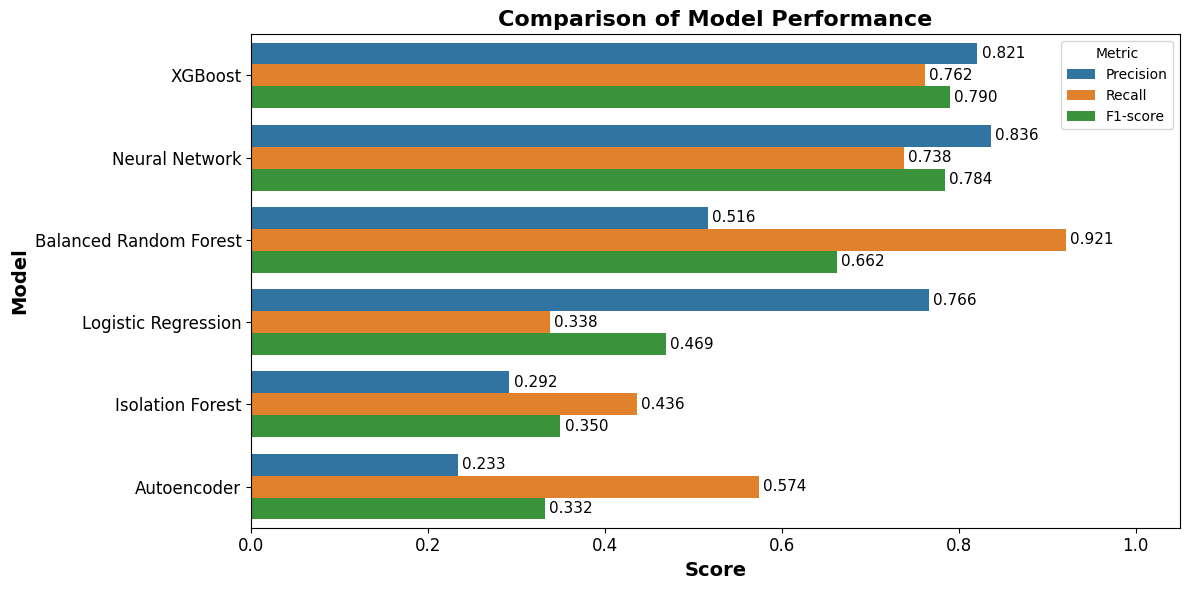

In [ ]:
# Sort models by F1-score (highest to lowest)
order_f1 = df_results.sort_values(by="F1-score", ascending=False).index

# Melt the DataFrame
df_melted = (df_results.reset_index().melt(id_vars="index", var_name="Metric", value_name="Score").rename(columns={"index": "Model"}))

# Create horizontal bar plot
plt.figure(figsize=(12, 6))
ax = sns.barplot(data=df_melted, y="Model", x="Score", hue="Metric", order=order_f1)

# Add values to the end of each bar
for container in ax.containers:
    ax.bar_label(container, fmt="%.3f", padding=3, fontsize=11)

# Bold title and axis labels
plt.title("Comparison of Model Performance", fontweight="bold")
plt.xlabel("Score", fontweight="bold")
plt.ylabel("Model", fontweight="bold")

# Bold title and axis labels
plt.title("Comparison of Model Performance", fontweight="bold", fontsize=16)
plt.xlabel("Score", fontweight="bold", fontsize=14)
plt.ylabel("Model", fontweight="bold", fontsize=14)
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)
plt.xlim(0, 1.05)
plt.tight_layout()
plt.show()


The six candidate models were compared using **Precision, Recall, and F1-score**, with **F1-score used as the primary model-selection criterion** because it provides a balance between Precision and Recall for the imbalanced anomaly-detection problem.

Among the evaluated models, **XGBoost achieved the highest F1-score of 0.790**, with a **Precision of 0.821** and a **Recall of 0.762**. This indicates that XGBoost provided the strongest overall balance between correctly identifying anomalous flights and limiting false-positive anomaly detections. The **Neural Network** achieved the highest Precision (**0.836**) and the second-highest F1-score (**0.784**), with a Recall of **0.738**. Its performance was therefore very close to that of XGBoost, although XGBoost achieved slightly higher Recall and F1-score.

Although **Balanced Random Forest (BRF)** achieved the highest Recall (**0.921**), its substantially lower Precision (**0.516**) resulted in a lower F1-score (**0.662**) and a greater number of false-positive anomaly detections. Nevertheless, **BRF** may be preferred in applications where minimizing missed anomalies is prioritized over reducing false alarms.

The remaining models demonstrated substantially lower F1-scores. **Logistic Regression** achieved an F1-score of **0.469**, followed by **Isolation Forest (0.350)** and the **Autoencoder (0.332)**. Although the Autoencoder achieved a Recall of **0.574**, its low Precision (**0.233**) substantially reduced its overall F1-score.

Based on these results, **XGBoost was selected as the final model** because it achieved the highest F1-score (**0.790**) while maintaining relatively high Precision (**0.821**) and Recall (**0.762**), providing the strongest overall trade-off between the two metrics among the six evaluated models.

# **STEP 5: FEATURE IMPORTANCE AND INTERPRETATION**


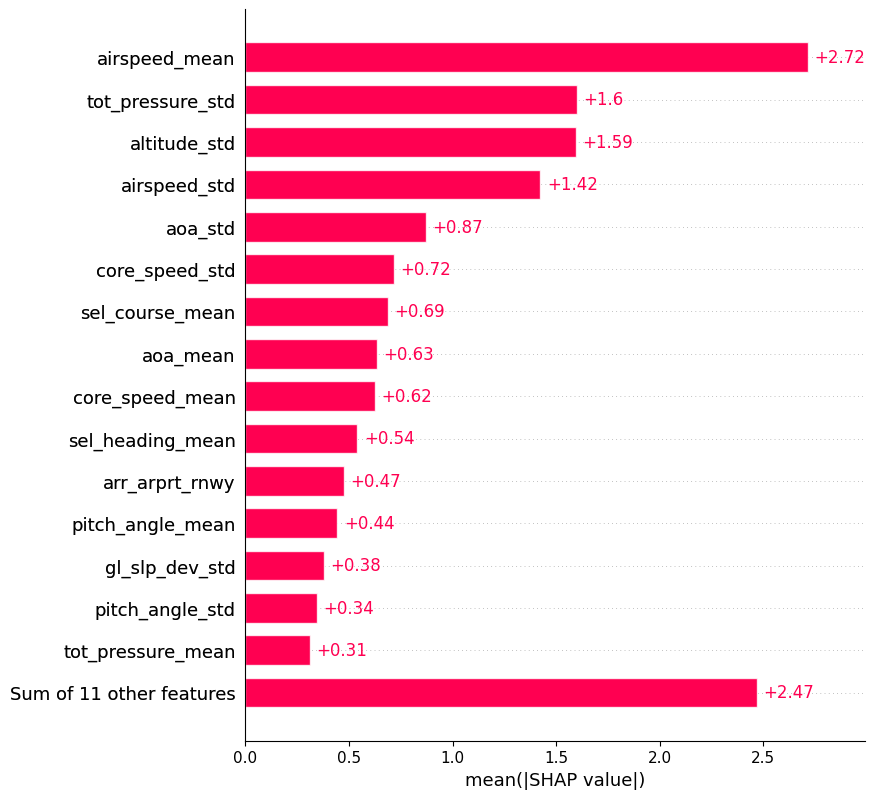

In [ ]:
# Create SHAP explainer for the trained XGBoost model
X_test_selected_df = pd.DataFrame(X_test_selected, columns=selected_features, index=X_test.index)
explainer = shap.TreeExplainer(xgb_optimal)
shap_values = explainer(X_test_selected_df)

# SHAP Global Feature Importance
shap.plots.bar(shap_values, max_display=16)


The **barplot** above shows **SHAP global feature-importance**. From the plot, `airspeed_mean` was found as the most influential predictor, with the highest mean absolute SHAP value (**2.72**), followed by `tot_pressure_std` (**1.60**), `altitude_std` (**1.59**), and `airspeed_std` (**1.42**). These results indicate that airspeed characteristics, total-pressure variability, and altitude variability have the strongest overall impact on the anomaly predictions. Other variables, including `aoa_std`, `core_speed_std`, and `sel_course_mean`, showed moderate contributions, while the remaining individual features had relatively smaller effects. The contextual airport-runway variable (`arr_arpt_rnwy`) also contributed to the model predictions, although its overall influence was lower than that of the leading flight-related variables. Since the bar plot represents **mean absolute SHAP values**, it reflects the magnitude of each feature's influence rather than the direction of its effect on the anomaly prediction.


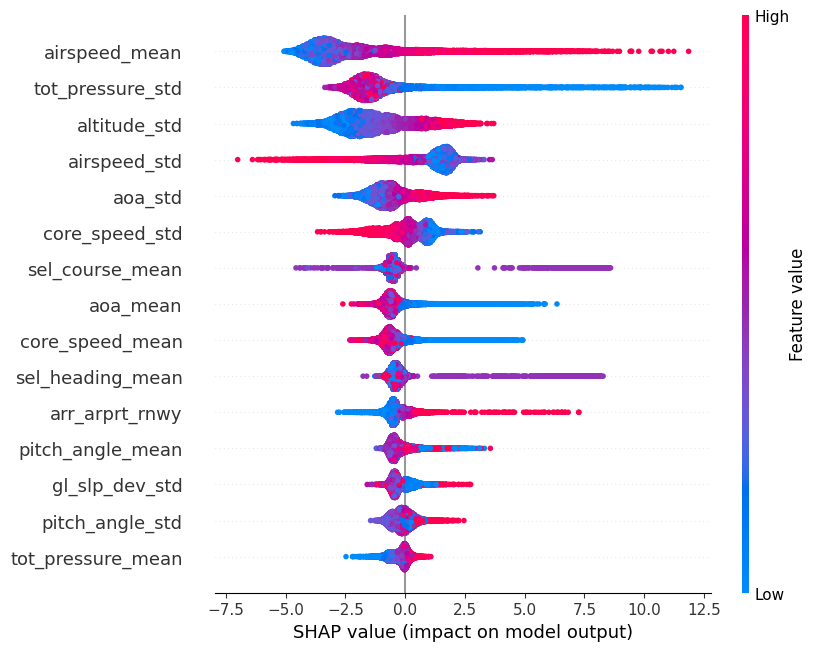

In [ ]:
# SHAP beeswarm plot
shap.plots.beeswarm(shap_values, max_display=15, group_remaining_features=False)


###**SHAP Feature Interpretation**

| Feature | Relative Importance | Effect of Higher Feature Values | Interpretation |
|---|---|---|---|
| `airspeed_mean` | Very High | ↑ Anomaly prediction | Higher mean airspeed generally increase the model output toward the anomaly class, while lower values have the opposite impact. |
| `tot_pressure_std` | Very High | ↓ Anomaly prediction | Higher variability in total pressure is associated with negative SHAP values, while lower values strongly increase the model output toward the anomaly class. |
| `altitude_std` | High | ↑ Anomaly prediction | Higher altitude variability increases the model output toward the anomaly class, whereas lower variability tends to decrease it. |
| `airspeed_std` | High | ↓ Anomaly prediction | Higher airspeed variability is mainly associated with negative SHAP values, while lower variability tends to increase the anomaly prediction. |
| `aoa_std` | Moderate–High | ↑ Anomaly prediction | Higher variability in angle of attack increases the model output toward the anomaly class. |
| `core_speed_std` | Moderate | ↓ Anomaly prediction | Higher core-speed variability generally decreases the model output, while lower values tend to increase it. |
| `sel_course_mean` | Moderate | Mixed / nonlinear | Most observations have relatively small effects, although some intermediate feature values produce large positive SHAP values. The relationship does not appear strongly monotonic. |
| `aoa_mean` | Moderate | ↓ Anomaly prediction | Lower mean angle-of-attack values are associated with relatively large positive SHAP values, while higher values generally decrease the anomaly prediction. |
| `core_speed_mean` | Moderate | ↓ Anomaly prediction | Lower mean core-speed values tend to increase the model output, while higher values generally decrease it. |
| `sel_heading_mean` | Moderate | Mixed / nonlinear | Most observations have limited influence, but some intermediate values produce relatively large positive SHAP values. |
| `arr_arpt_rnwy` | Lower–Moderate | Category-dependent | Some encoded airport-runway values increase the model output substantially, while others have little or negative influence, indicating that anomaly predictions vary across airport-runway contexts. |
| `pitch_angle_mean` | Lower | Mixed | The effect is concentrated near zero, with some observations producing positive or negative contributions depending on feature value. |
| `gl_slp_dev_std` | Lower | Mixed | Most effects are relatively small, although some higher values are associated with positive contributions to anomaly prediction. |
| `pitch_angle_std` | Lower | ↑ Anomaly prediction | Higher pitch-angle variability generally tends to increase the model output, although its overall contribution is relatively small. |
| `tot_pressure_mean` | Lower | ↑ Anomaly prediction | Higher mean total pressure generally produces positive SHAP values, while lower values tend to decrease the model output; its overall importance is relatively small. |

# **RECOMMENDATIONS FOR FUTURE WORK**

Future work could benefit from incorporating additional **airport-specific operational characteristics** into the prediction models, such as airport traffic volume, number of runways, runway configuration, and weather conditions. These factors may influence the likelihood and characteristics of flight anomalies. In addition, incorporating **aircraft-specific characteristics**, such as aircraft model, aircraft age, and engine type, may further improve model performance, as different aircraft types may exhibit different approach dynamics, deceleration behavior, and flap-deployment procedures.

A primary direction for future work is to investigate the **three anomaly categories separately: Speed High, Path High, and Flaps Late**. In the present study, these categories were combined into a single anomaly class to formulate the problem as a binary anomaly-detection task. Although this approach simplified model development and enabled an overall assessment of anomalous versus normal flights, combining the three categories resulted in the loss of **anomaly-type-specific information**. In particular, the predictors and operational conditions associated with one type of anomaly may differ from those associated with another. Future work will therefore develop **multiclass classification models**, e.g., multinomial logistic regression model, to distinguish among normal flights and the three individual anomaly categories **(Speed High, Path High, and Flaps Late)**. This approach could provide a more detailed understanding of the contributing factors associated with each type of anomalous flight behavior.

A second direction for future work is to preserve the **temporal structure of the flight trajectories**. In the present study, approximately 160 time-stamped observations within each flight trajectory were aggregated into flight-level features using summary statistics such as the **mean and standard deviation**. While this aggregation provides a compact representation of each flight and facilitates the application of conventional machine-learning models, it may obscure important temporal patterns, short-duration deviations, and the sequence of events occurring during the flight. Future work will therefore investigate the use of the **unaggregated time-series data** and develop a sequential anomaly-detection model, such as an **LSTM-based autoencoder (Long Short-Term Memory Autoencoder)**. The predictive performance of the LSTM autoencoder can then be compared with the machine-learning and autoencoder models developed in the present study to determine whether explicitly modeling the temporal dynamics of the flight trajectories improves anomaly detection.

# **REFERENCES**

Campesato, O. (2023). Python 3 and Feature Engineering.

Galli, S. (2020). Python feature engineering cookbook. Packt Publishing.

Galli, S. (2021). Feature-engine: A Python package for feature engineering for machine learning. Journal of Open Source Software, 6(65), p.3642.

Hosseinpour, M., Sahebi, S., Zamzuri, Z. H., Yahaya, A. S., & Ismail, N. (2018). Predicting crash frequency for multi-vehicle collision types using multivariate Poisson-lognormal spatial model: A comparative analysis. *Accident Analysis & Prevention, 118*, 277–288. [Link](https://www.sciencedirect.com/science/article/abs/pii/S0001457518301878)


Hosseinpour, M., Madsen, T. K. O., Olesen, A. V., & Lahrmann, H. (2021). An in-depth analysis of self-reported cycling injuries in single and multiparty bicycle crashes in Denmark. *Journal of Safety Research, 77*, 114–124. [Link](https://www.sciencedirect.com/science/article/abs/pii/S0022437521000244)

Lee, H., Li, G., Rai, A. and Chattopadhyay, A., 2020. Real-time anomaly detection framework using a support vector regression for the safety monitoring of commercial aircraft. Advanced Engineering Informatics, 44, p.101071.

Kim, M., Kho, S.Y. and Kim, D.K., 2017. Hierarchical ordered model for injury severity of pedestrian crashes in South Korea. Journal of safety research, 61, pp.33-40.

Memarzadeh, M., Matthews, B. and Templin, T., 2022. Multiclass anomaly detection in flight data using semi-supervised explainable deep learning model. Journal of Aerospace Information Systems, 19(2), pp.83-97.

Shaheed, M.S., Gkritza, K., Carriquiry, A.L. and Hallmark, S.L., 2016. Analysis of occupant injury severity in winter weather crashes: A fully Bayesian multivariate approach. Analytic methods in accident research, 11, pp.33-47.
